# Customer Churn Intelligence Platform

## Project Overview

Customer churn is a major challenge for subscription-based businesses.
Predicting customers who are likely to discontinue their subscriptions can
help organizations take proactive retention actions.

This project develops an end-to-end customer churn analytics and prediction
platform using Machine Learning and Deep Learning techniques.

The project includes:

- Exploratory Data Analysis
- Data preprocessing and feature engineering
- Feature selection
- Machine Learning model comparison
- Hyperparameter tuning
- Deep Learning-based churn prediction
- Explainable AI using SHAP
- Business-oriented churn insights
- Interactive Tableau dashboard
- Streamlit-based prediction application
- Model deployment

The objective is to build an accurate, interpretable and deployable churn
prediction solution that can support customer retention decisions.

## Business Problem

Subscription-based companies lose revenue when customers cancel their services.

The goal of this project is to:

1. Identify customers who are likely to churn.
2. Determine the major factors associated with churn.
3. Compare different Machine Learning and Deep Learning approaches.
4. Select an appropriate predictive model.
5. Provide actionable business recommendations for reducing customer churn.

### Target Variable

The target variable is:

- `Churn Value`
  - `0` → Customer retained
  - `1` → Customer churned

In [1]:
# ==============================
# Import Required Libraries
# ==============================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

%pip install -q scikit-learn==1.6.1 xgboost==3.0.2 shap==0.51.0

# Display settings
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print("Libraries imported successfully.")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 253.9/253.9 MB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 21.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 351.5/351.5 MB 4.3 MB/s eta 0:00:00
Libraries imported successfully.


In [2]:
from pathlib import Path
import pandas as pd

try:
    from google.colab import files

    uploaded = files.upload()

    if not uploaded:
        raise RuntimeError("No dataset was uploaded.")

    DATA_PATH = Path(next(iter(uploaded.keys())))

except ImportError:
    candidates = [
        Path("Telco_customer_churn.csv"),
        Path("../Telco_customer_churn.csv")
    ]

    DATA_PATH = next(
        (path for path in candidates if path.exists()),
        None
    )

    if DATA_PATH is None:
        raise FileNotFoundError(
            "Telco_customer_churn.csv was not found."
        )

df = pd.read_csv(DATA_PATH)

print("Dataset loaded from:", DATA_PATH)
print("Dataset shape:", df.shape)

Saving Telco_customer_churn.csv to Telco_customer_churn (1).csv
Dataset loaded from: Telco_customer_churn (1).csv
Dataset shape: (7043, 33)


In [3]:
print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nDataset Information:")
df.info()

Dataset Shape: (7043, 33)

First 5 Rows:


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null   object 
 16  In

In [4]:
print("\nColumn Names:")
print(df.columns.tolist())


Column Names:
['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code', 'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value', 'Churn Score', 'CLTV', 'Churn Reason']


In [5]:
print("\nDuplicate Rows:", df.duplicated().sum())


Duplicate Rows: 0


In [6]:
print("\nBasic Statistical Summary:")
display(df.describe(include='all').T)


Basic Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
CustomerID,7043,7043,3186-AJIEK,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Count,7043.0,NaN,NaN,NaN,1.0,0.0,1.0,1.0,1.0,1.0,1.0
Country,7043,1,United States,7043,NaN,NaN,NaN,NaN,NaN,NaN,NaN
State,7043,1,California,7043,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City,7043,1129,Los Angeles,305,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Zip Code,7043.0,NaN,NaN,NaN,93521.964646,1865.794555,90001.0,92102.0,93552.0,95351.0,96161.0
Lat Long,7043,1652,"34.159534, -116.425984",5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Latitude,7043.0,NaN,NaN,NaN,36.282441,2.455723,32.555828,34.030915,36.391777,38.224869,41.962127
Longitude,7043.0,NaN,NaN,NaN,-119.79888,2.157889,-124.301372,-121.815412,-119.730885,-118.043237,-114.192901
Gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
print("Churn Value Distribution:")
print(df['Churn Value'].value_counts())

print("\nChurn Percentage:")
print(df['Churn Value'].value_counts(normalize=True) * 100)

Churn Value Distribution:
Churn Value
0    5174
1    1869
Name: count, dtype: int64

Churn Percentage:
Churn Value
0    73.463013
1    26.536987
Name: proportion, dtype: float64


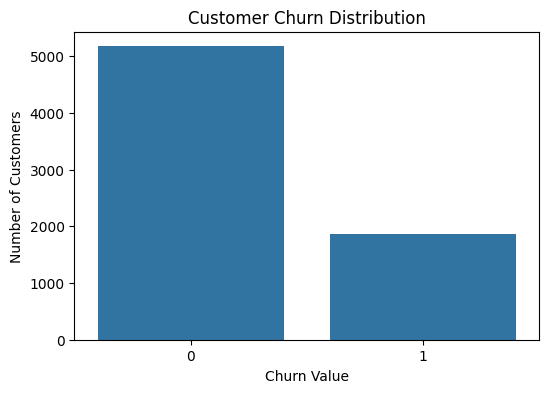

In [8]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x='Churn Value')

plt.title('Customer Churn Distribution')
plt.xlabel('Churn Value')
plt.ylabel('Number of Customers')

plt.show()

In [9]:
print("Dataset Shape:", df.shape)
print(df.columns.tolist())
print(df['Churn Value'].value_counts())
print(df['Churn Value'].value_counts(normalize=True) * 100)

Dataset Shape: (7043, 33)
['CustomerID', 'Count', 'Country', 'State', 'City', 'Zip Code', 'Lat Long', 'Latitude', 'Longitude', 'Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Label', 'Churn Value', 'Churn Score', 'CLTV', 'Churn Reason']
Churn Value
0    5174
1    1869
Name: count, dtype: int64
Churn Value
0    73.463013
1    26.536987
Name: proportion, dtype: float64


In [10]:
# Check missing values
missing_values = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': (df.isnull().sum() / len(df)) * 100
})

missing_values = missing_values[missing_values['Missing Count'] > 0]

display(missing_values)

,Missing Count,Missing Percentage
Churn Reason,5174,73.463013


In [11]:
# Check blank/empty strings
blank_counts = {}

for col in df.select_dtypes(include='object').columns:
    blank_counts[col] = (df[col].astype(str).str.strip() == '').sum()

blank_counts = pd.Series(blank_counts)
blank_counts = blank_counts[blank_counts > 0]

display(blank_counts)

,0
Total Charges,11


In [12]:
# Data types
dtype_summary = pd.DataFrame({
    'Data Type': df.dtypes,
    'Unique Values': df.nunique()
})

display(dtype_summary)

,Data Type,Unique Values
CustomerID,object,7043
Count,int64,1
Country,object,1
State,object,1
City,object,1129
Zip Code,int64,1652
Lat Long,object,1652
Latitude,float64,1652
Longitude,float64,1651
Gender,object,2


In [13]:
categorical_columns = df.select_dtypes(include='object').columns

for col in categorical_columns:
    print(f"\n{'='*50}")
    print(f"{col}")
    print(f"{'='*50}")
    print(df[col].value_counts().head(15))


CustomerID
CustomerID
3186-AJIEK    1
3668-QPYBK    1
9237-HQITU    1
7203-OYKCT    1
9837-FWLCH    1
9710-NJERN    1
4807-IZYOZ    1
1471-GIQKQ    1
0666-UXTJO    1
9053-EJUNL    1
1685-BQULA    1
6691-CCIHA    1
2274-XUATA    1
9347-AERRL    1
6075-SLNIL    1
Name: count, dtype: int64

Country
Country
United States    7043
Name: count, dtype: int64

State
State
California    7043
Name: count, dtype: int64

City
City
Los Angeles      305
San Diego        150
San Jose         112
Sacramento       108
San Francisco    104
Fresno            64
Long Beach        60
Oakland           52
Stockton          44
Bakersfield       40
Glendale          40
Berkeley          32
Riverside         32
Pasadena          30
Whittier          30
Name: count, dtype: int64

Lat Long
Lat Long
34.159534, -116.425984    5
33.28156, -115.955541     5
34.201108, -116.593456    5
33.798266, -118.300237    5
33.391181, -118.421305    5
33.989524, -118.089299    5
33.940619, -117.9513      5
33.976678, -118.06587

In [14]:
numeric_columns = df.select_dtypes(include=np.number).columns

print("Numerical Columns:")
print(numeric_columns.tolist())

Numerical Columns:
['Count', 'Zip Code', 'Latitude', 'Longitude', 'Tenure Months', 'Monthly Charges', 'Churn Value', 'Churn Score', 'CLTV']


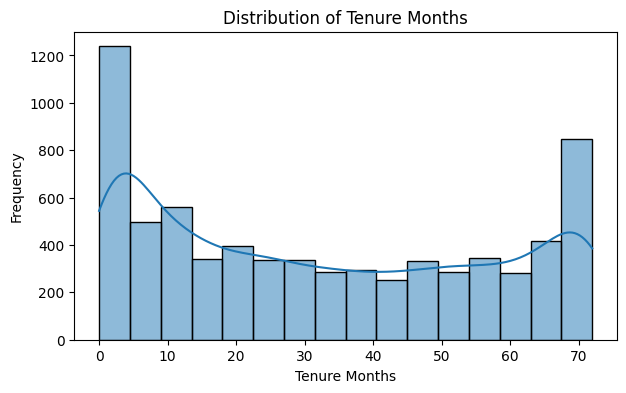

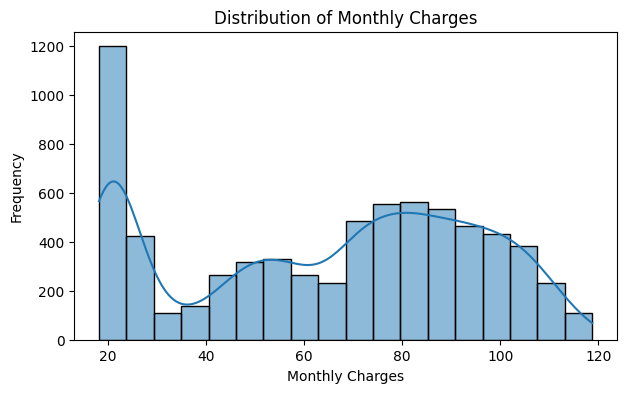

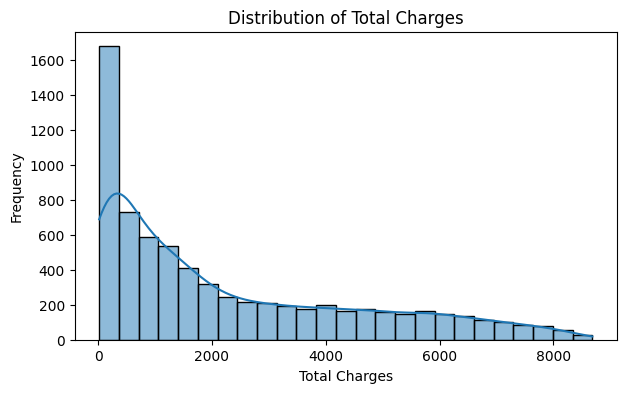

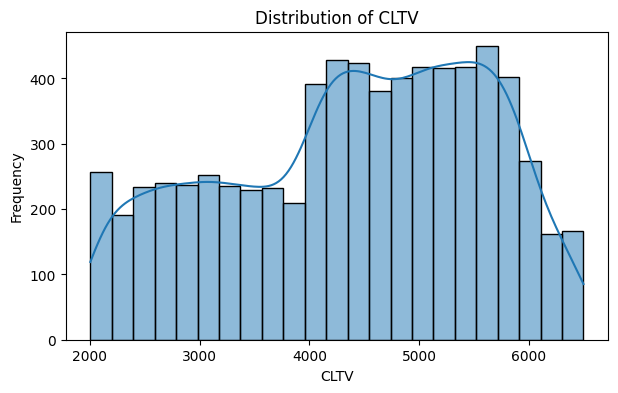

In [15]:
numerical_features = [
    'Tenure Months',
    'Monthly Charges',
    'Total Charges',
    'CLTV'
]

# Convert Total Charges temporarily for visualization
eda_df = df.copy()
eda_df['Total Charges'] = pd.to_numeric(
    eda_df['Total Charges'],
    errors='coerce'
)

for col in numerical_features:
    plt.figure(figsize=(7, 4))
    sns.histplot(data=eda_df, x=col, kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

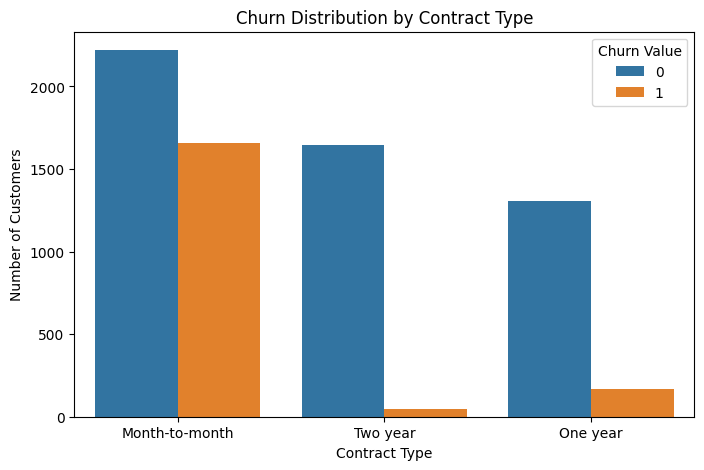

In [16]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='Contract',
    hue='Churn Value'
)

plt.title('Churn Distribution by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')

plt.show()

Contract
Month-to-month    42.709677
One year          11.269518
Two year           2.831858
Name: Churn Value, dtype: float64


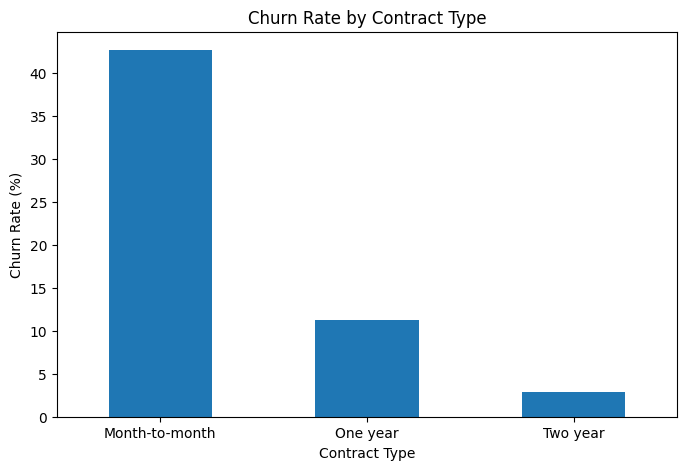

In [17]:
contract_churn = (
    df.groupby('Contract')['Churn Value']
      .mean()
      .sort_values(ascending=False) * 100
)

print(contract_churn)

plt.figure(figsize=(8, 5))

contract_churn.plot(kind='bar')

plt.title('Churn Rate by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)

plt.show()

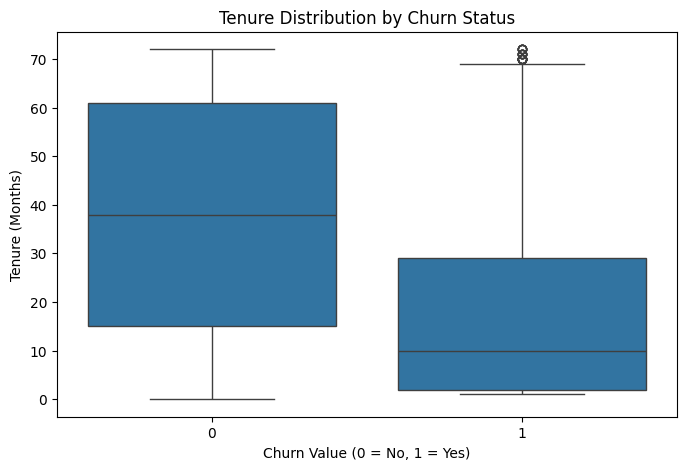

In [18]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=eda_df,
    x='Churn Value',
    y='Tenure Months'
)

plt.title('Tenure Distribution by Churn Status')
plt.xlabel('Churn Value (0 = No, 1 = Yes)')
plt.ylabel('Tenure (Months)')

plt.show()

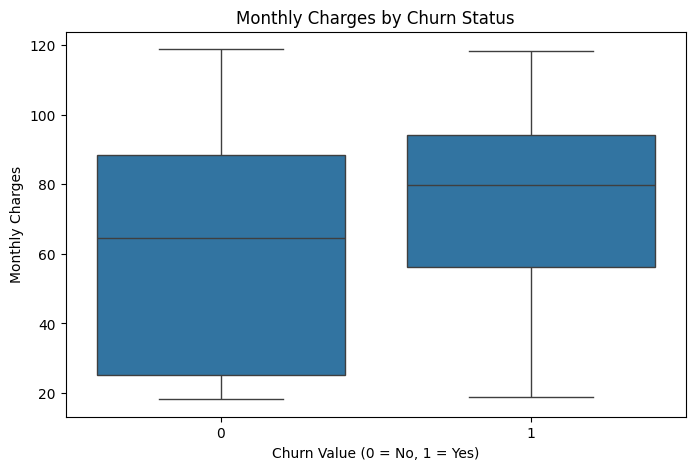

In [19]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=eda_df,
    x='Churn Value',
    y='Monthly Charges'
)

plt.title('Monthly Charges by Churn Status')
plt.xlabel('Churn Value (0 = No, 1 = Yes)')
plt.ylabel('Monthly Charges')

plt.show()

Internet Service
Fiber optic    41.892765
DSL            18.959108
No              7.404980
Name: Churn Value, dtype: float64


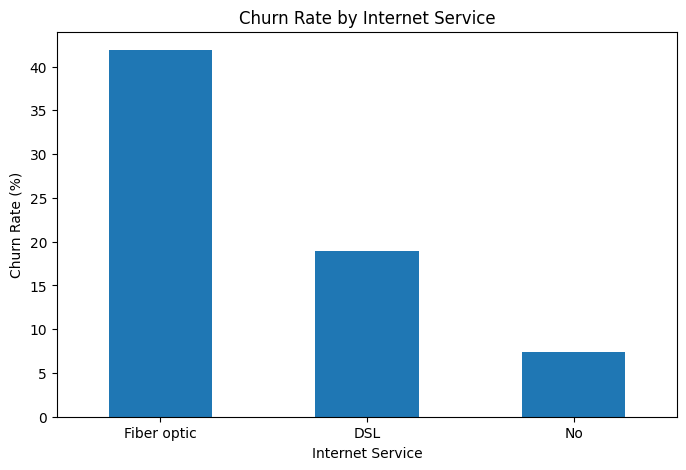

In [20]:
internet_churn = (
    df.groupby('Internet Service')['Churn Value']
      .mean()
      .sort_values(ascending=False) * 100
)

print(internet_churn)

plt.figure(figsize=(8, 5))

internet_churn.plot(kind='bar')

plt.title('Churn Rate by Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=0)

plt.show()

Payment Method
Electronic check             45.285412
Mailed check                 19.106700
Bank transfer (automatic)    16.709845
Credit card (automatic)      15.243101
Name: Churn Value, dtype: float64


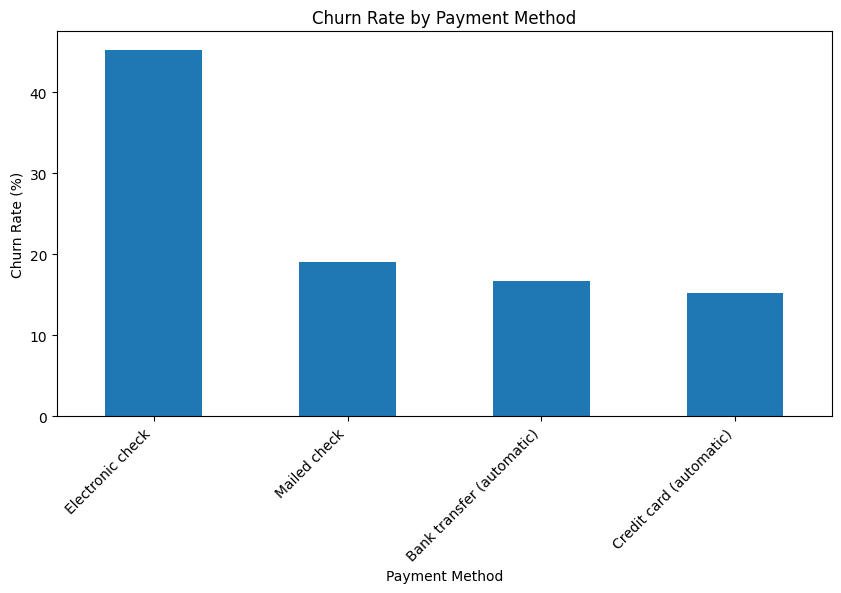

In [21]:
payment_churn = (
    df.groupby('Payment Method')['Churn Value']
      .mean()
      .sort_values(ascending=False) * 100
)

print(payment_churn)

plt.figure(figsize=(10, 5))

payment_churn.plot(kind='bar')

plt.title('Churn Rate by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=45, ha='right')

plt.show()

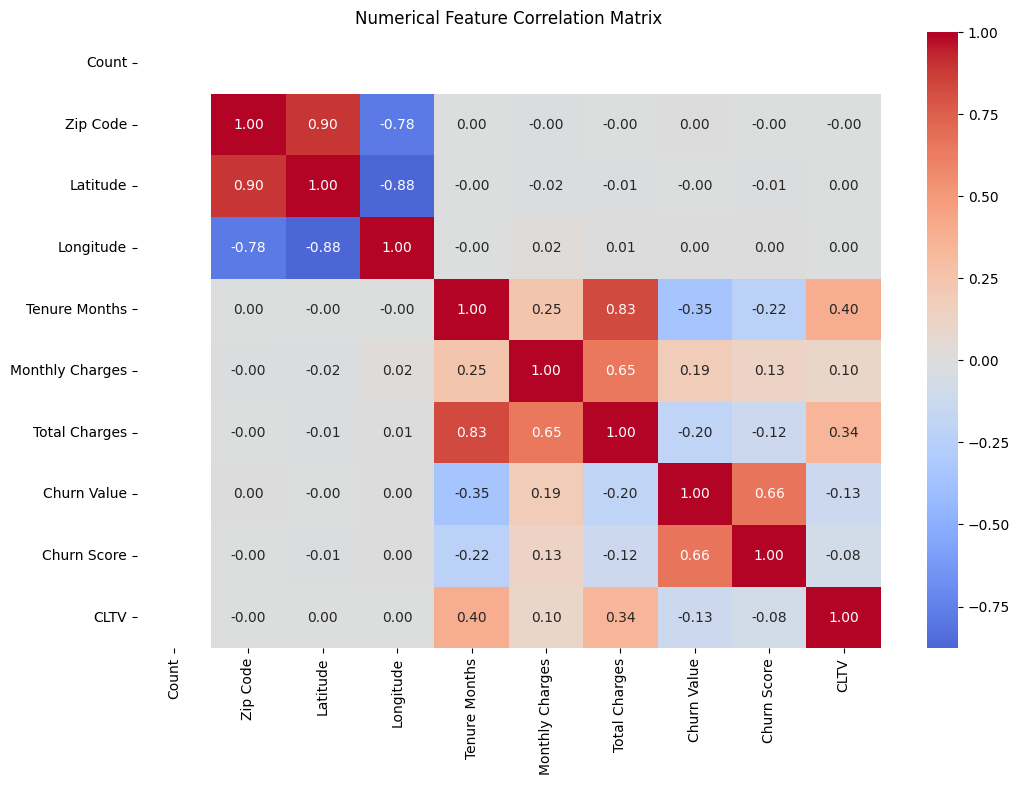

In [22]:
corr_df = df.copy()

corr_df['Total Charges'] = pd.to_numeric(
    corr_df['Total Charges'],
    errors='coerce'
)

numeric_corr = corr_df.select_dtypes(include=np.number).corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Numerical Feature Correlation Matrix')
plt.show()

## 9. Data Cleaning & Leakage Analysis

Before model development, the dataset is cleaned and evaluated for
potential data leakage, irrelevant identifiers, high-cardinality geographic
variables, and variables that may not be available at the time a churn
prediction is generated.

The objective is to ensure that the predictive model learns from
customer characteristics and service usage information rather than
post-churn information or identifiers.

In [23]:
df_model = df.copy()

print("Original dataset shape:", df_model.shape)

Original dataset shape: (7043, 33)


In [24]:
columns_to_drop = [
    'CustomerID',
    'Count',
    'Country',
    'State',
    'City',
    'Zip Code',
    'Lat Long',
    'Latitude',
    'Longitude',
    'Churn Label',
    'Churn Score',
    'Churn Reason'
]

df_model.drop(columns=columns_to_drop, inplace=True)

print("Shape after removing identifiers/geographic/leakage columns:")
print(df_model.shape)

print("\nRemaining columns:")
print(df_model.columns.tolist())

Shape after removing identifiers/geographic/leakage columns:
(7043, 21)

Remaining columns:
['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Tenure Months', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method', 'Monthly Charges', 'Total Charges', 'Churn Value', 'CLTV']


In [25]:
print(df_model[['CLTV', 'Churn Value']].head())

print("\nCLTV statistics:")
print(df_model['CLTV'].describe())

   CLTV  Churn Value
0  3239            1
1  2701            1
2  5372            1
3  5003            1
4  5340            1

CLTV statistics:
count    7043.000000
mean     4400.295755
std      1183.057152
min      2003.000000
25%      3469.000000
50%      4527.000000
75%      5380.500000
max      6500.000000
Name: CLTV, dtype: float64


In [26]:
df_model['Total Charges'] = pd.to_numeric(
    df_model['Total Charges'],
    errors='coerce'
)

print(df_model['Total Charges'].dtype)
print("Missing Total Charges:", df_model['Total Charges'].isna().sum())

float64
Missing Total Charges: 11


In [27]:
display(
    df_model[df_model['Total Charges'].isna()]
)

,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Value,CLTV
2234,Female,No,Yes,No,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,0,2578
2438,Male,No,No,No,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,0,5504
2568,Female,No,Yes,No,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,0,2048
2667,Male,No,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,0,4950
2856,Female,No,Yes,No,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,0,4740
4331,Male,No,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,0,2019
4687,Male,No,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,0,2299
5104,Female,No,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,0,3763
5719,Male,No,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,0,4890
6772,Female,No,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,0,2342


In [28]:
df_model.dropna(inplace=True)

print("Final cleaned dataset shape:", df_model.shape)
print("Remaining missing values:", df_model.isnull().sum().sum())

Final cleaned dataset shape: (7032, 21)
Remaining missing values: 0


In [29]:
# Final prediction features: exclude target and CLTV.
# CLTV remains in df_model for exploratory analysis if needed.
X = df_model.drop(
    columns=['Churn Value', 'CLTV']
)

y = df_model['Churn Value']

print("Raw predictors:", X.shape[1])
print("CLTV used by model:", 'CLTV' in X.columns)
print("Target shape:", y.shape)

assert X.shape[1] == 19
assert 'CLTV' not in X.columns

Raw predictors: 19
CLTV used by model: False
Target shape: (7032,)


## 10. Train-Test Split

The cleaned dataset is divided into training and testing sets using an
80:20 stratified split.

Stratification is used to preserve the original churn-to-non-churn ratio
in both subsets. All preprocessing and feature selection steps will be
fitted only on the training data to prevent data leakage.

In [30]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nTesting set:")
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

Training set:
X_train: (5625, 19)
y_train: (5625,)

Testing set:
X_test: (1407, 19)
y_test: (1407,)


In [31]:
print("Training target distribution:")
print(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True) * 100)

Training target distribution:
Churn Value
0    73.422222
1    26.577778
Name: proportion, dtype: float64

Testing target distribution:
Churn Value
0    73.418621
1    26.581379
Name: proportion, dtype: float64


## 11. Feature Type Identification

The predictor variables are divided into numerical and categorical
features. Numerical variables will be processed using appropriate
numeric preprocessing, while categorical variables will be encoded
using one-hot encoding.

A Scikit-learn preprocessing pipeline will be used so that the same
transformations are consistently applied to training, validation, and
future unseen data.

In [32]:
numeric_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['object']
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

print("\nNumber of numerical features:", len(numeric_features))
print("Number of categorical features:", len(categorical_features))

Numerical features:
['Tenure Months', 'Monthly Charges', 'Total Charges']

Categorical features:
['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method']

Number of numerical features: 3
Number of categorical features: 16


In [33]:
print(X_train.shape)
print(X_test.shape)

print("\nNumerical:")
print(numeric_features)

print("\nCategorical:")
print(categorical_features)

(5625, 19)
(1407, 19)

Numerical:
['Tenure Months', 'Monthly Charges', 'Total Charges']

Categorical:
['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method']


## 12. Preprocessing Pipeline

A Scikit-learn `ColumnTransformer` is used to apply different preprocessing
operations to numerical and categorical variables.

Numerical variables are standardized using `StandardScaler`, while
categorical variables are converted into numerical representations using
one-hot encoding.

The preprocessing transformer is fitted only on the training data to
prevent data leakage.

In [34]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

In [35]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            'num',
            StandardScaler(),
            numeric_features
        ),
        (
            'cat',
            OneHotEncoder(
                handle_unknown='ignore',
                drop='first',
                sparse_output=False
            ),
            categorical_features
        )
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [36]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (5625, 30)
Processed testing shape: (1407, 30)


In [37]:
feature_names = preprocessor.get_feature_names_out()

print("Number of processed features:", len(feature_names))

print("\nFirst 30 processed features:")
print(feature_names[:30])

Number of processed features: 30

First 30 processed features:
['num__Tenure Months' 'num__Monthly Charges' 'num__Total Charges'
 'cat__Gender_Male' 'cat__Senior Citizen_Yes' 'cat__Partner_Yes'
 'cat__Dependents_Yes' 'cat__Phone Service_Yes'
 'cat__Multiple Lines_No phone service' 'cat__Multiple Lines_Yes'
 'cat__Internet Service_Fiber optic' 'cat__Internet Service_No'
 'cat__Online Security_No internet service' 'cat__Online Security_Yes'
 'cat__Online Backup_No internet service' 'cat__Online Backup_Yes'
 'cat__Device Protection_No internet service' 'cat__Device Protection_Yes'
 'cat__Tech Support_No internet service' 'cat__Tech Support_Yes'
 'cat__Streaming TV_No internet service' 'cat__Streaming TV_Yes'
 'cat__Streaming Movies_No internet service' 'cat__Streaming Movies_Yes'
 'cat__Contract_One year' 'cat__Contract_Two year'
 'cat__Paperless Billing_Yes'
 'cat__Payment Method_Credit card (automatic)'
 'cat__Payment Method_Electronic check' 'cat__Payment Method_Mailed check']


In [38]:
X_train_processed_df = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

display(X_train_processed_df.head())

,num__Tenure Months,num__Monthly Charges,num__Total Charges,cat__Gender_Male,cat__Senior Citizen_Yes,cat__Partner_Yes,cat__Dependents_Yes,cat__Phone Service_Yes,cat__Multiple Lines_No phone service,cat__Multiple Lines_Yes,cat__Internet Service_Fiber optic,cat__Internet Service_No,cat__Online Security_No internet service,cat__Online Security_Yes,cat__Online Backup_No internet service,cat__Online Backup_Yes,cat__Device Protection_No internet service,cat__Device Protection_Yes,cat__Tech Support_No internet service,cat__Tech Support_Yes,cat__Streaming TV_No internet service,cat__Streaming TV_Yes,cat__Streaming Movies_No internet service,cat__Streaming Movies_Yes,cat__Contract_One year,cat__Contract_Two year,cat__Paperless Billing_Yes,cat__Payment Method_Credit card (automatic),cat__Payment Method_Electronic check,cat__Payment Method_Mailed check
2907,1.321816,0.981556,1.659900,1.0,0.0,1.0,1.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
7014,-0.267410,-0.971546,-0.562252,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4346,1.444064,0.837066,1.756104,0.0,0.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
5186,-1.204646,0.641092,-0.908326,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
4485,0.669826,-0.808787,-0.101561,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [39]:
print("Processed dataset shape:")
print(X_train_processed_df.shape)

Processed dataset shape:
(5625, 30)


In [40]:
print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)
print("Number of processed features:", len(feature_names))
print(feature_names)

Processed training shape: (5625, 30)
Processed testing shape: (1407, 30)
Number of processed features: 30
['num__Tenure Months' 'num__Monthly Charges' 'num__Total Charges'
 'cat__Gender_Male' 'cat__Senior Citizen_Yes' 'cat__Partner_Yes'
 'cat__Dependents_Yes' 'cat__Phone Service_Yes'
 'cat__Multiple Lines_No phone service' 'cat__Multiple Lines_Yes'
 'cat__Internet Service_Fiber optic' 'cat__Internet Service_No'
 'cat__Online Security_No internet service' 'cat__Online Security_Yes'
 'cat__Online Backup_No internet service' 'cat__Online Backup_Yes'
 'cat__Device Protection_No internet service' 'cat__Device Protection_Yes'
 'cat__Tech Support_No internet service' 'cat__Tech Support_Yes'
 'cat__Streaming TV_No internet service' 'cat__Streaming TV_Yes'
 'cat__Streaming Movies_No internet service' 'cat__Streaming Movies_Yes'
 'cat__Contract_One year' 'cat__Contract_Two year'
 'cat__Paperless Billing_Yes'
 'cat__Payment Method_Credit card (automatic)'
 'cat__Payment Method_Electronic check' '

## 13. Baseline Machine Learning Models

Three supervised learning algorithms are evaluated as baseline models:

- Decision Tree
- Random Forest
- Support Vector Machine (SVM)

The models are evaluated using Accuracy, Precision, Recall, F1-score,
ROC-AUC and PR-AUC. Since the churn dataset is moderately imbalanced,
metrics beyond accuracy are considered when comparing model performance.

In [41]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

In [42]:
dt_model = DecisionTreeClassifier(
    random_state=42
)

rf_model = RandomForestClassifier(
    random_state=42
)

svm_model = SVC(
    probability=True,
    random_state=42
)

In [43]:
# Train Decision Tree
dt_model.fit(X_train_processed, y_train)

# Train Random Forest
rf_model.fit(X_train_processed, y_train)

# Train SVM
svm_model.fit(X_train_processed, y_train)

print("All baseline models trained successfully.")

All baseline models trained successfully.


In [44]:
# Predictions
dt_pred = dt_model.predict(X_test_processed)
rf_pred = rf_model.predict(X_test_processed)
svm_pred = svm_model.predict(X_test_processed)

# Probability predictions
dt_prob = dt_model.predict_proba(X_test_processed)[:, 1]
rf_prob = rf_model.predict_proba(X_test_processed)[:, 1]
svm_prob = svm_model.predict_proba(X_test_processed)[:, 1]

print("Predictions generated successfully.")

Predictions generated successfully.


In [45]:
def evaluate_model(name, y_true, y_pred, y_prob):
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1-Score': f1_score(y_true, y_pred),
        'ROC-AUC': roc_auc_score(y_true, y_prob),
        'PR-AUC': average_precision_score(y_true, y_prob)
    }

In [46]:
baseline_results = []

baseline_results.append(
    evaluate_model(
        'Decision Tree',
        y_test,
        dt_pred,
        dt_prob
    )
)

baseline_results.append(
    evaluate_model(
        'Random Forest',
        y_test,
        rf_pred,
        rf_prob
    )
)

baseline_results.append(
    evaluate_model(
        'SVM',
        y_test,
        svm_pred,
        svm_prob
    )
)

baseline_df = pd.DataFrame(baseline_results)

display(
    baseline_df.style.format({
        'Accuracy': '{:.4f}',
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'F1-Score': '{:.4f}',
        'ROC-AUC': '{:.4f}',
        'PR-AUC': '{:.4f}'
    })
)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Decision Tree,0.7193,0.4733,0.4973,0.4850,0.6482,0.3690
1,Random Forest,0.7903,0.6304,0.5107,0.5643,0.8278,0.6083
2,SVM,0.7960,0.6426,0.5241,0.5773,0.8011,0.6220


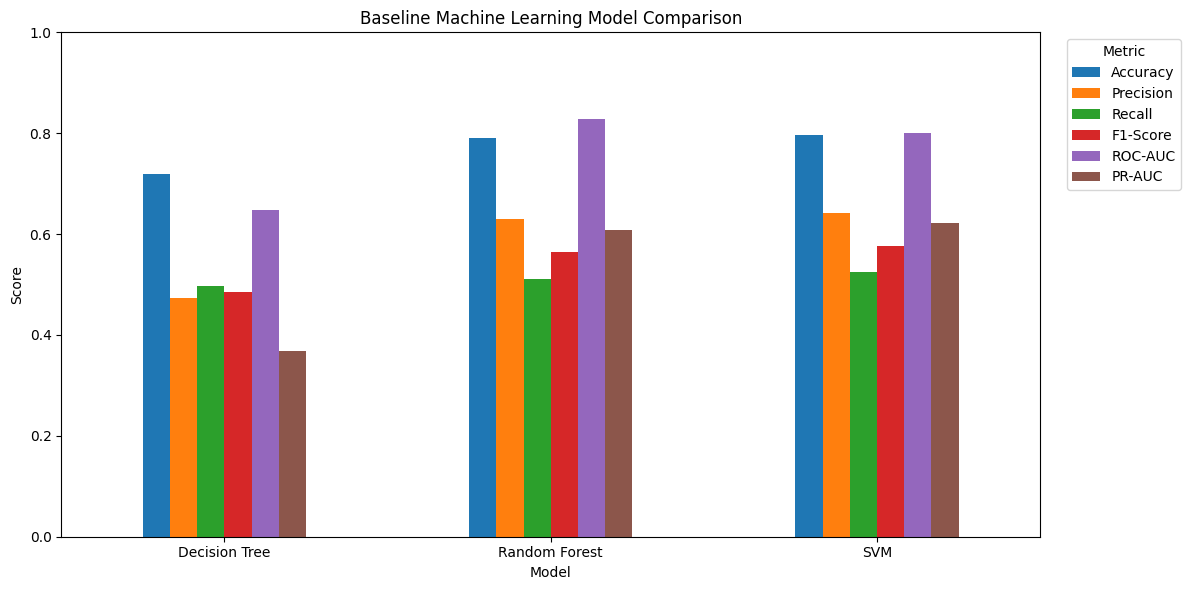

In [47]:
metrics = [
    'Accuracy',
    'Precision',
    'Recall',
    'F1-Score',
    'ROC-AUC',
    'PR-AUC'
]

baseline_plot = baseline_df.set_index('Model')[metrics]

ax = baseline_plot.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Baseline Machine Learning Model Comparison')
plt.xlabel('Model')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.legend(title='Metric', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [48]:
from sklearn.metrics import classification_report

print("Decision Tree Classification Report")
print("=" * 50)
print(classification_report(y_test, dt_pred))

print("\nRandom Forest Classification Report")
print("=" * 50)
print(classification_report(y_test, rf_pred))

print("\nSVM Classification Report")
print("=" * 50)
print(classification_report(y_test, svm_pred))

Decision Tree Classification Report
              precision    recall  f1-score   support

           0       0.81      0.80      0.81      1033
           1       0.47      0.50      0.49       374

    accuracy                           0.72      1407
   macro avg       0.64      0.65      0.65      1407
weighted avg       0.72      0.72      0.72      1407


Random Forest Classification Report
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1033
           1       0.63      0.51      0.56       374

    accuracy                           0.79      1407
   macro avg       0.73      0.70      0.71      1407
weighted avg       0.78      0.79      0.78      1407


SVM Classification Report
              precision    recall  f1-score   support

           0       0.84      0.89      0.87      1033
           1       0.64      0.52      0.58       374

    accuracy                           0.80      1407
   macro avg       0.74     


Decision Tree


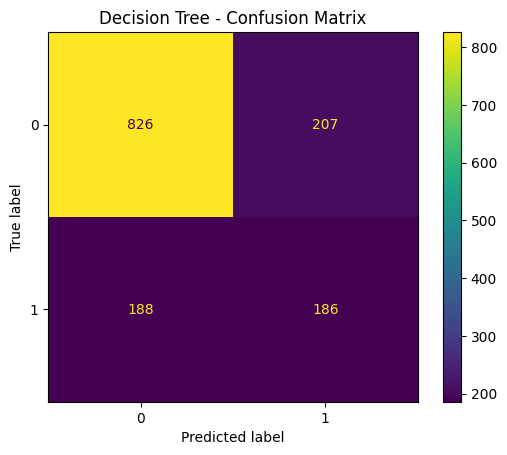


Random Forest


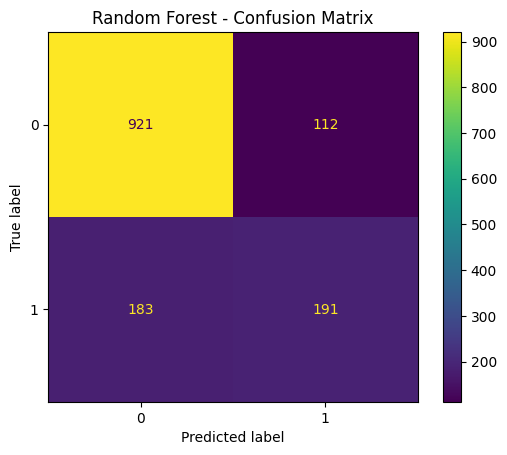


SVM


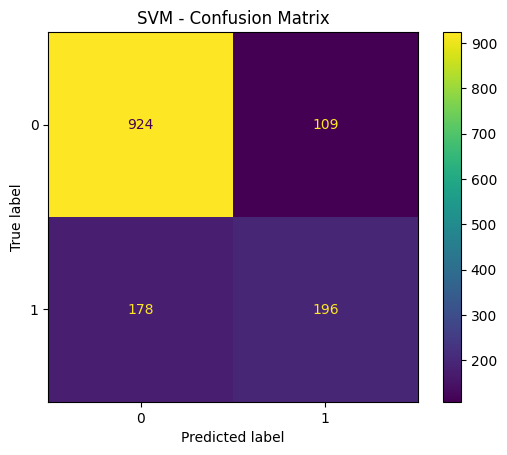

In [49]:
from sklearn.metrics import ConfusionMatrixDisplay

models_predictions = [
    ('Decision Tree', dt_pred),
    ('Random Forest', rf_pred),
    ('SVM', svm_pred)
]

for name, predictions in models_predictions:
    print(f"\n{name}")

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions
    )

    plt.title(f'{name} - Confusion Matrix')
    plt.show()

## 14. Stratified K-Fold Cross-Validation

To obtain a more reliable estimate of model performance, 5-fold stratified
cross-validation is performed on the training dataset.

Stratification ensures that each fold maintains a similar proportion of
churned and non-churned customers.

The models are evaluated using Accuracy, Precision, Recall, F1-score,
ROC-AUC and PR-AUC.

In [50]:
from sklearn.model_selection import StratifiedKFold, cross_validate

In [51]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print(cv)

StratifiedKFold(n_splits=5, random_state=42, shuffle=True)


In [52]:
scoring = {
    'accuracy': 'accuracy',
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc',
    'pr_auc': 'average_precision'
}

In [53]:
def cross_validate_model(model, X_data, y_data, model_name):

    cv_results = cross_validate(
        model,
        X_data,
        y_data,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    return {
        'Model': model_name,
        'Accuracy': cv_results['test_accuracy'].mean(),
        'Precision': cv_results['test_precision'].mean(),
        'Recall': cv_results['test_recall'].mean(),
        'F1-Score': cv_results['test_f1'].mean(),
        'ROC-AUC': cv_results['test_roc_auc'].mean(),
        'PR-AUC': cv_results['test_pr_auc'].mean()
    }

In [54]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

# Identify columns from the raw training data
numeric_cv = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_cv = [
    col for col in X_train.columns
    if col not in numeric_cv
]

# Fit preprocessing separately within each CV fold
def make_cv_pipeline(estimator):
    fold_preprocessor = ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), numeric_cv),
            (
                "cat",
                OneHotEncoder(
                    handle_unknown="ignore",
                    drop="first",
                    sparse_output=False
                ),
                categorical_cv
            )
        ]
    )

    return Pipeline([
        ("preprocessor", fold_preprocessor),
        ("classifier", estimator)
    ])


cv_model_specs = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "SVM": SVC(probability=True, random_state=42)
}

cv_results = []

for model_name, estimator in cv_model_specs.items():
    pipeline = make_cv_pipeline(estimator)

    cv_results.append(
        cross_validate_model(
            pipeline,
            X_train,       # Raw data, not X_train_processed
            y_train,
            model_name
        )
    )

cv_df = pd.DataFrame(cv_results)

display(
    cv_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "PR-AUC": "{:.4f}"
    })
)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Decision Tree,0.7346,0.5008,0.5191,0.5094,0.6663,0.3887
1,Random Forest,0.8018,0.6597,0.5251,0.5846,0.8418,0.6454
2,SVM,0.8091,0.6874,0.5177,0.5905,0.8300,0.6660


In [55]:
comparison = baseline_df.copy()

comparison['Evaluation'] = 'Test Set'

cv_display = cv_df.copy()
cv_display['Evaluation'] = '5-Fold CV'

combined_results = pd.concat(
    [comparison, cv_display],
    ignore_index=True
)

display(
    combined_results.style.format({
        'Accuracy': '{:.4f}',
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'F1-Score': '{:.4f}',
        'ROC-AUC': '{:.4f}',
        'PR-AUC': '{:.4f}'
    })
)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,Evaluation
0,Decision Tree,0.7193,0.4733,0.4973,0.4850,0.6482,0.3690,Test Set
1,Random Forest,0.7903,0.6304,0.5107,0.5643,0.8278,0.6083,Test Set
2,SVM,0.7960,0.6426,0.5241,0.5773,0.8011,0.6220,Test Set
3,Decision Tree,0.7346,0.5008,0.5191,0.5094,0.6663,0.3887,5-Fold CV
4,Random Forest,0.8018,0.6597,0.5251,0.5846,0.8418,0.6454,5-Fold CV
5,SVM,0.8091,0.6874,0.5177,0.5905,0.8300,0.6660,5-Fold CV


## 15. Feature Selection

Feature selection is performed to identify informative predictors while
reducing unnecessary dimensionality.

Two approaches are evaluated:

1. Correlation-based feature selection
2. Recursive Feature Elimination (RFE)

Feature selection is performed using the training data only to avoid
information leakage from the test set.

In [56]:
# Create a DataFrame containing processed training features
X_train_processed_df = pd.DataFrame(
    X_train_processed,
    columns=feature_names,
    index=X_train.index
)

# Add target
correlation_data = X_train_processed_df.copy()
correlation_data['Churn Value'] = y_train

# Calculate correlation with target
target_correlation = (
    correlation_data.corr()['Churn Value']
    .drop('Churn Value')
    .sort_values(key=abs, ascending=False)
)

display(target_correlation.to_frame('Correlation'))

,Correlation
num__Tenure Months,-0.351710
cat__Internet Service_Fiber optic,0.306416
cat__Payment Method_Electronic check,0.305342
cat__Contract_Two year,-0.301801
cat__Dependents_Yes,-0.254806
cat__Internet Service_No,-0.227420
cat__Device Protection_No internet service,-0.227420
cat__Tech Support_No internet service,-0.227420
cat__Streaming Movies_No internet service,-0.227420
cat__Streaming TV_No internet service,-0.227420


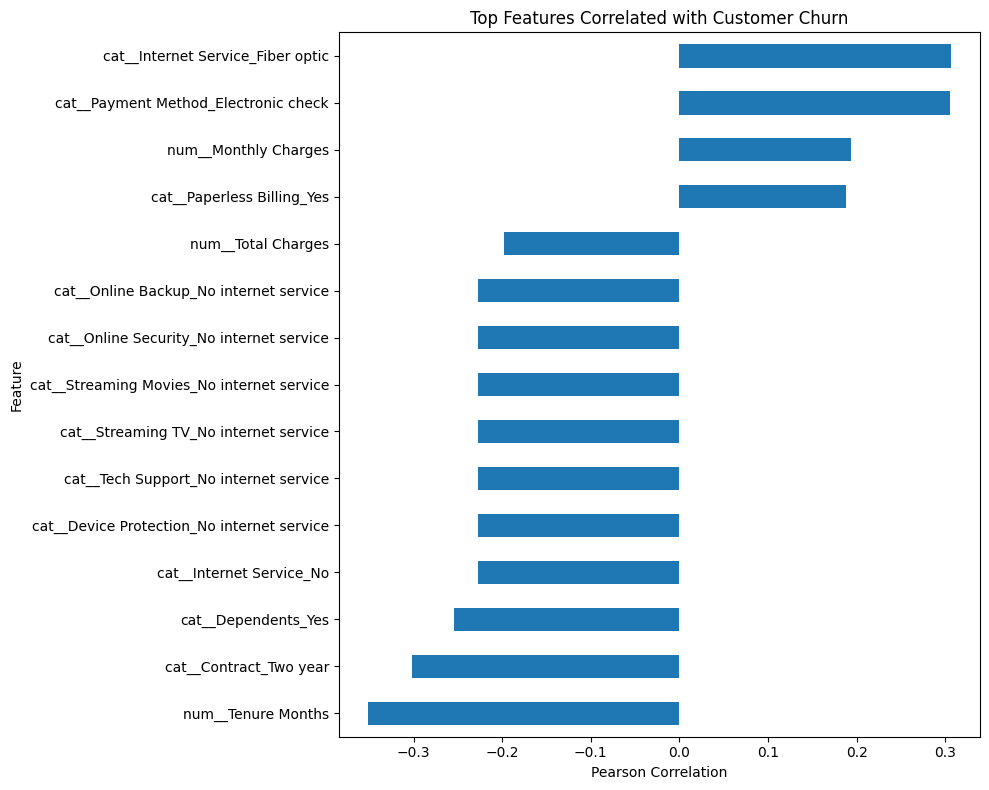

In [57]:
plt.figure(figsize=(10, 8))

top_corr = target_correlation.head(15).sort_values()

top_corr.plot(kind='barh')

plt.title('Top Features Correlated with Customer Churn')
plt.xlabel('Pearson Correlation')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()

In [58]:
correlation_threshold = 0.05

correlation_features = target_correlation[
    target_correlation.abs() >= correlation_threshold
].index.tolist()

print("Correlation threshold:", correlation_threshold)
print("Selected features:", len(correlation_features))

print("\nSelected features:")
for feature in correlation_features:
    print(feature)

Correlation threshold: 0.05
Selected features: 26

Selected features:
num__Tenure Months
cat__Internet Service_Fiber optic
cat__Payment Method_Electronic check
cat__Contract_Two year
cat__Dependents_Yes
cat__Internet Service_No
cat__Device Protection_No internet service
cat__Tech Support_No internet service
cat__Streaming Movies_No internet service
cat__Streaming TV_No internet service
cat__Online Security_No internet service
cat__Online Backup_No internet service
num__Total Charges
num__Monthly Charges
cat__Paperless Billing_Yes
cat__Contract_One year
cat__Online Security_Yes
cat__Tech Support_Yes
cat__Partner_Yes
cat__Senior Citizen_Yes
cat__Payment Method_Credit card (automatic)
cat__Payment Method_Mailed check
cat__Online Backup_Yes
cat__Streaming TV_Yes
cat__Streaming Movies_Yes
cat__Device Protection_Yes


In [59]:
X_train_corr = X_train_processed_df[correlation_features]
X_test_corr = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)[correlation_features]

print("Correlation-selected training shape:", X_train_corr.shape)
print("Correlation-selected testing shape:", X_test_corr.shape)

Correlation-selected training shape: (5625, 26)
Correlation-selected testing shape: (1407, 26)


In [60]:
from sklearn.feature_selection import RFE

In [61]:
rfe_estimator = DecisionTreeClassifier(
    random_state=42
)

In [62]:
rfe = RFE(
    estimator=rfe_estimator,
    n_features_to_select=15
)

rfe.fit(X_train_processed_df, y_train)

RFE(estimator=DecisionTreeClassifier(random_state=42), n_features_to_select=15)

In [63]:
rfe_features = X_train_processed_df.columns[rfe.support_].tolist()

print("Number of RFE-selected features:", len(rfe_features))

print("\nRFE selected features:")
for feature in rfe_features:
    print(feature)

Number of RFE-selected features: 15

RFE selected features:
num__Tenure Months
num__Monthly Charges
num__Total Charges
cat__Gender_Male
cat__Senior Citizen_Yes
cat__Partner_Yes
cat__Dependents_Yes
cat__Multiple Lines_Yes
cat__Internet Service_Fiber optic
cat__Online Security_Yes
cat__Online Backup_Yes
cat__Tech Support_Yes
cat__Paperless Billing_Yes
cat__Payment Method_Credit card (automatic)
cat__Payment Method_Electronic check


In [64]:
X_train_rfe = X_train_processed_df[rfe_features]

X_test_rfe = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)[rfe_features]

print("RFE training shape:", X_train_rfe.shape)
print("RFE testing shape:", X_test_rfe.shape)

RFE training shape: (5625, 15)
RFE testing shape: (1407, 15)


## 16. Model Performance with Feature Selection

Decision Tree, Random Forest and SVM are evaluated using three feature
sets:

- Full processed feature set
- Correlation-selected feature set
- RFE-selected feature set

The same evaluation metrics are used across all experiments to enable
a fair comparison.

In [65]:
# ==========================================
# Model Comparison Across Feature Sets
# ==========================================

models = {
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'SVM': SVC(probability=True, random_state=42)
}

feature_sets = {
    'Full Features': (X_train_processed_df,
                      pd.DataFrame(
                          X_test_processed,
                          columns=feature_names,
                          index=X_test.index
                      )),

    'Correlation Features': (X_train_corr, X_test_corr),

    'RFE Features': (X_train_rfe, X_test_rfe)
}

feature_results = []

for feature_set_name, (X_tr, X_te) in feature_sets.items():

    for model_name, model in models.items():

        model.fit(X_tr, y_train)

        predictions = model.predict(X_te)
        probabilities = model.predict_proba(X_te)[:, 1]

        result = evaluate_model(
            model_name,
            y_test,
            predictions,
            probabilities
        )

        result['Feature Set'] = feature_set_name
        result['Number of Features'] = X_tr.shape[1]

        feature_results.append(result)

feature_comparison_df = pd.DataFrame(feature_results)

feature_comparison_df = feature_comparison_df[
    [
        'Model',
        'Feature Set',
        'Number of Features',
        'Accuracy',
        'Precision',
        'Recall',
        'F1-Score',
        'ROC-AUC',
        'PR-AUC'
    ]
]

display(
    feature_comparison_df.style.format({
        'Accuracy': '{:.4f}',
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'F1-Score': '{:.4f}',
        'ROC-AUC': '{:.4f}',
        'PR-AUC': '{:.4f}'
    })
)

,Model,Feature Set,Number of Features,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Decision Tree,Full Features,30,0.7193,0.4733,0.4973,0.4850,0.6482,0.3690
1,Random Forest,Full Features,30,0.7903,0.6304,0.5107,0.5643,0.8278,0.6083
2,SVM,Full Features,30,0.7960,0.6426,0.5241,0.5773,0.8011,0.6220
3,Decision Tree,Correlation Features,26,0.7313,0.4947,0.5000,0.4973,0.6579,0.3809
4,Random Forest,Correlation Features,26,0.7839,0.6136,0.5053,0.5543,0.8256,0.6033
5,SVM,Correlation Features,26,0.8038,0.6601,0.5401,0.5941,0.8004,0.6298
6,Decision Tree,RFE Features,15,0.7342,0.5000,0.4920,0.4960,0.6567,0.3810
7,Random Forest,RFE Features,15,0.7839,0.6182,0.4893,0.5463,0.8221,0.6057
8,SVM,RFE Features,15,0.7939,0.6511,0.4840,0.5552,0.8095,0.6271


In [66]:
roc_comparison = feature_comparison_df.sort_values(
    by='ROC-AUC',
    ascending=False
)

display(
    roc_comparison.style.format({
        'Accuracy': '{:.4f}',
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'F1-Score': '{:.4f}',
        'ROC-AUC': '{:.4f}',
        'PR-AUC': '{:.4f}'
    })
)

,Model,Feature Set,Number of Features,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
1,Random Forest,Full Features,30,0.7903,0.6304,0.5107,0.5643,0.8278,0.6083
4,Random Forest,Correlation Features,26,0.7839,0.6136,0.5053,0.5543,0.8256,0.6033
7,Random Forest,RFE Features,15,0.7839,0.6182,0.4893,0.5463,0.8221,0.6057
8,SVM,RFE Features,15,0.7939,0.6511,0.4840,0.5552,0.8095,0.6271
2,SVM,Full Features,30,0.7960,0.6426,0.5241,0.5773,0.8011,0.6220
5,SVM,Correlation Features,26,0.8038,0.6601,0.5401,0.5941,0.8004,0.6298
3,Decision Tree,Correlation Features,26,0.7313,0.4947,0.5000,0.4973,0.6579,0.3809
6,Decision Tree,RFE Features,15,0.7342,0.5000,0.4920,0.4960,0.6567,0.3810
0,Decision Tree,Full Features,30,0.7193,0.4733,0.4973,0.4850,0.6482,0.3690


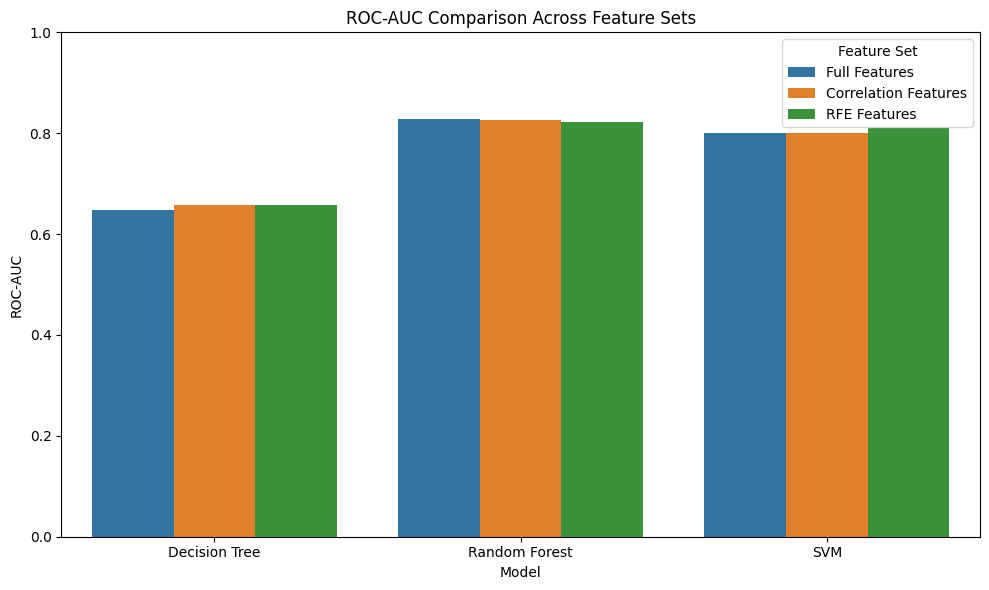

In [67]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_comparison_df,
    x='Model',
    y='ROC-AUC',
    hue='Feature Set'
)

plt.title('ROC-AUC Comparison Across Feature Sets')
plt.xlabel('Model')
plt.ylabel('ROC-AUC')
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

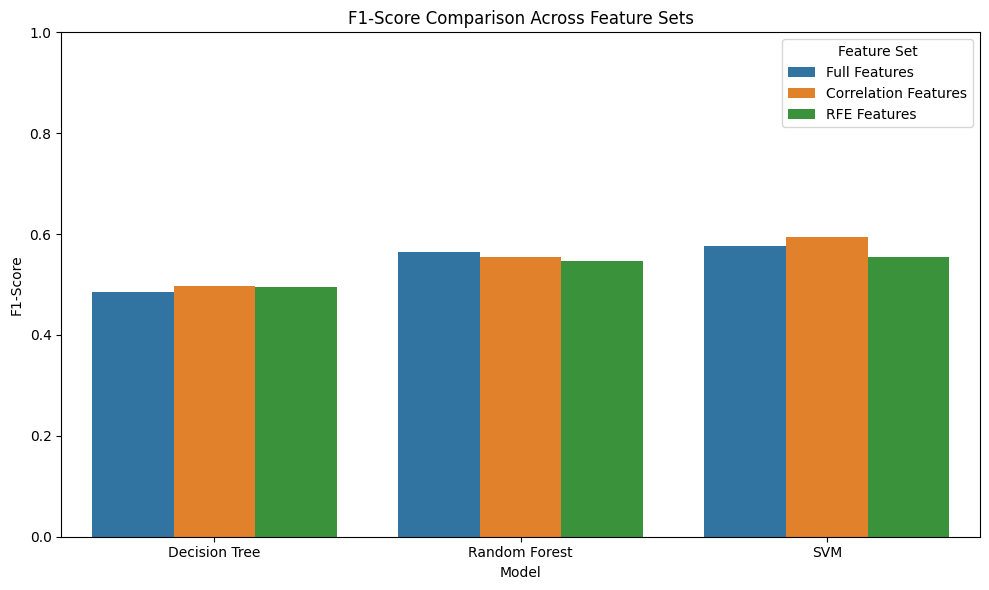

In [68]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_comparison_df,
    x='Model',
    y='F1-Score',
    hue='Feature Set'
)

plt.title('F1-Score Comparison Across Feature Sets')
plt.xlabel('Model')
plt.ylabel('F1-Score')
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

In [69]:
best_roc = feature_comparison_df.loc[
    feature_comparison_df['ROC-AUC'].idxmax()
]

print("Best configuration based on ROC-AUC:")
print(best_roc)

Best configuration based on ROC-AUC:
Model                 Random Forest
Feature Set           Full Features
Number of Features               30
Accuracy                   0.790334
Precision                  0.630363
Recall                     0.510695
F1-Score                   0.564254
ROC-AUC                    0.827835
PR-AUC                     0.608276
Name: 1, dtype: object


In [70]:
best_f1 = feature_comparison_df.loc[
    feature_comparison_df['F1-Score'].idxmax()
]

print("\nBest configuration based on F1-Score:")
print(best_f1)


Best configuration based on F1-Score:
Model                                  SVM
Feature Set           Correlation Features
Number of Features                      26
Accuracy                          0.803838
Precision                         0.660131
Recall                            0.540107
F1-Score                          0.594118
ROC-AUC                            0.80037
PR-AUC                             0.62984
Name: 5, dtype: object


## 17. Advanced Machine Learning — XGBoost

XGBoost (Extreme Gradient Boosting) is evaluated as an advanced
tree-based ensemble model.

Unlike Random Forest, which builds trees independently and averages
their predictions, gradient boosting builds trees sequentially, with
each new tree attempting to improve the errors made by the previous
trees.

An untuned XGBoost model is first evaluated using the same processed
full feature set. Hyperparameter optimization will be performed later.

In [71]:
from xgboost import XGBClassifier

print("XGBoost imported successfully.")

XGBoost imported successfully.


In [72]:
xgb_model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    objective='binary:logistic',
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

print(xgb_model)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.05, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=4, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=200, n_jobs=-1,
              num_parallel_tree=None, ...)


In [73]:
xgb_model.fit(
    X_train_processed,
    y_train
)

print("XGBoost model trained successfully.")

XGBoost model trained successfully.


In [74]:
xgb_pred = xgb_model.predict(X_test_processed)

xgb_prob = xgb_model.predict_proba(
    X_test_processed
)[:, 1]

print("XGBoost predictions generated.")

XGBoost predictions generated.


In [75]:
xgb_result = evaluate_model(
    'XGBoost',
    y_test,
    xgb_pred,
    xgb_prob
)

xgb_result_df = pd.DataFrame([xgb_result])

display(
    xgb_result_df.style.format({
        'Accuracy': '{:.4f}',
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'F1-Score': '{:.4f}',
        'ROC-AUC': '{:.4f}',
        'PR-AUC': '{:.4f}'
    })
)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,XGBoost,0.7989,0.6383,0.5615,0.5974,0.8455,0.6560


In [76]:
ml_baseline_comparison = pd.concat(
    [
        baseline_df,
        xgb_result_df
    ],
    ignore_index=True
)

display(
    ml_baseline_comparison.style.format({
        'Accuracy': '{:.4f}',
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'F1-Score': '{:.4f}',
        'ROC-AUC': '{:.4f}',
        'PR-AUC': '{:.4f}'
    })
)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Decision Tree,0.7193,0.4733,0.4973,0.4850,0.6482,0.3690
1,Random Forest,0.7903,0.6304,0.5107,0.5643,0.8278,0.6083
2,SVM,0.7960,0.6426,0.5241,0.5773,0.8011,0.6220
3,XGBoost,0.7989,0.6383,0.5615,0.5974,0.8455,0.6560


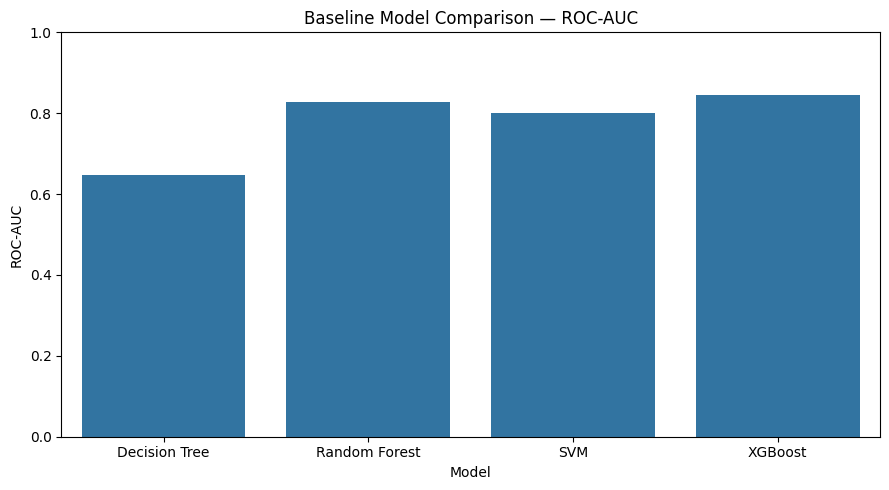

In [77]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=ml_baseline_comparison,
    x='Model',
    y='ROC-AUC'
)

plt.title('Baseline Model Comparison — ROC-AUC')
plt.xlabel('Model')
plt.ylabel('ROC-AUC')
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

In [78]:
xgb_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': xgb_model.feature_importances_
}).sort_values(
    by='Importance',
    ascending=False
)

display(xgb_importance.head(15))

,Feature,Importance
10,cat__Internet Service_Fiber optic,0.187398
25,cat__Contract_Two year,0.146972
11,cat__Internet Service_No,0.091841
12,cat__Online Security_No internet service,0.074805
24,cat__Contract_One year,0.074765
6,cat__Dependents_Yes,0.059611
16,cat__Device Protection_No internet service,0.056820
0,num__Tenure Months,0.040092
28,cat__Payment Method_Electronic check,0.040039
23,cat__Streaming Movies_Yes,0.024965


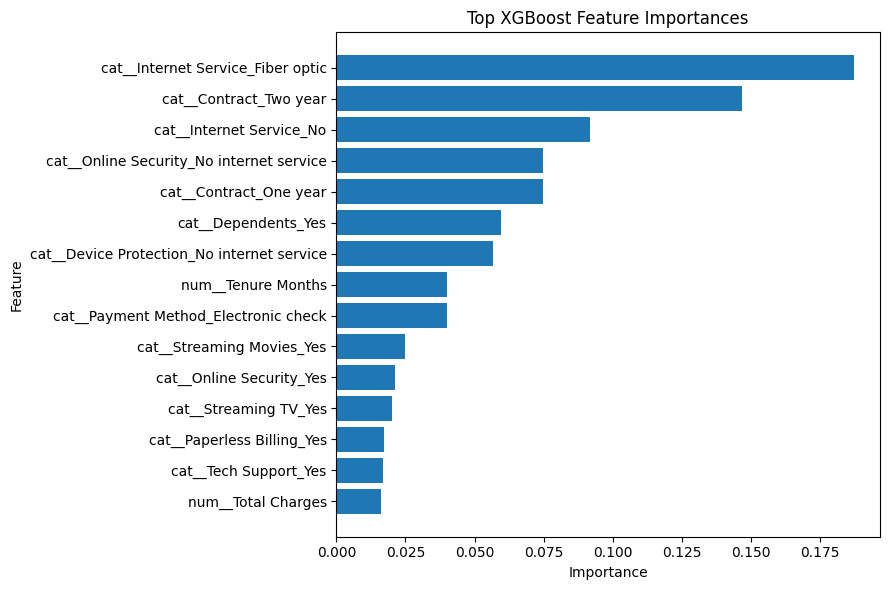

In [79]:
plt.figure(figsize=(9, 6))

top_xgb = xgb_importance.head(15).sort_values('Importance')

plt.barh(
    top_xgb['Feature'],
    top_xgb['Importance']
)

plt.title('Top XGBoost Feature Importances')
plt.xlabel('Importance')
plt.ylabel('Feature')

plt.tight_layout()
plt.show()

## 18. Deep Learning — Artificial Neural Network

An Artificial Neural Network (ANN) is developed to evaluate whether a
deep learning approach can improve churn prediction on the processed
tabular dataset.

The network consists of fully connected dense layers with dropout
regularization. A sigmoid output layer produces the probability of
customer churn.

The ANN is trained using binary cross-entropy loss and evaluated using
the same metrics as the Machine Learning models.

In [80]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [81]:
ann_model = Sequential([

    Dense(
        64,
        activation='relu',
        input_shape=(X_train_processed.shape[1],)
    ),

    Dropout(0.30),

    Dense(
        32,
        activation='relu'
    ),

    Dropout(0.20),

    Dense(
        1,
        activation='sigmoid'
    )
])

ann_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=[
        'accuracy',
        tf.keras.metrics.AUC(name='auc')
    ]
)

ann_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,097 (16.00 KB)

 Trainable params: 4,097 (16.00 KB)

 Non-trainable params: 0 (0.00 B)

In [82]:
early_stopping = EarlyStopping(
    monitor='val_auc',
    mode='max',
    patience=20,
    min_delta=0.0005,
    restore_best_weights=True
)

In [83]:
history = ann_model.fit(
    X_train_processed,
    y_train,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1
)

print(
    "Training stopped after:",
    len(history.history['loss']),
    "epochs"
)

Epoch 1/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7262 - auc: 0.7311 - loss: 0.5239 - val_accuracy: 0.7956 - val_auc: 0.8389 - val_loss: 0.4218
Epoch 2/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7956 - auc: 0.8232 - loss: 0.4427 - val_accuracy: 0.7964 - val_auc: 0.8501 - val_loss: 0.4103
Epoch 3/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7996 - auc: 0.8347 - loss: 0.4299 - val_accuracy: 0.8062 - val_auc: 0.8587 - val_loss: 0.3983
Epoch 4/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8022 - auc: 0.8438 - loss: 0.4199 - val_accuracy: 0.8080 - val_auc: 0.8633 - val_loss: 0.3943
Epoch 5/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8020 - auc: 0.8454 - loss: 0.4188 - val_accuracy: 0.8071 - val_auc: 0.8621 - val_loss: 0.3940
Epoch 6/100
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8049 - auc: 0.8514 - loss: 0.4115 - val_accuracy: 0.8000 - val_auc: 0.8625 - val_loss: 0.3937
Epoch 7/100
141/141 ━━━━━━━━━━━━━━

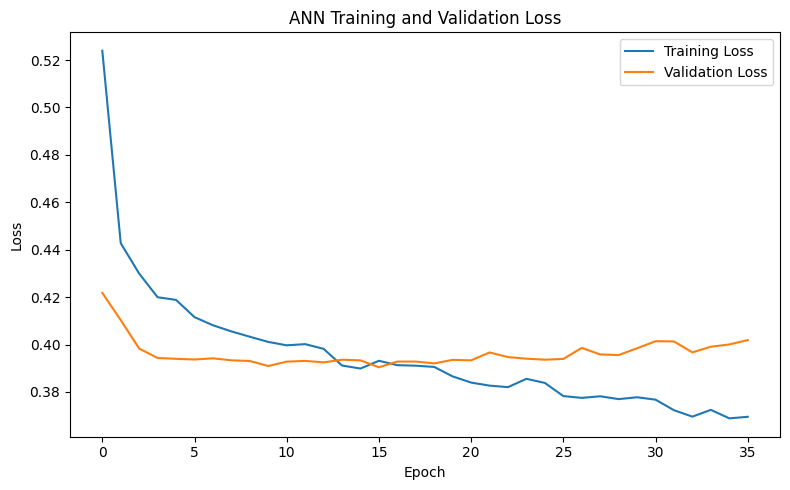

In [84]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title('ANN Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

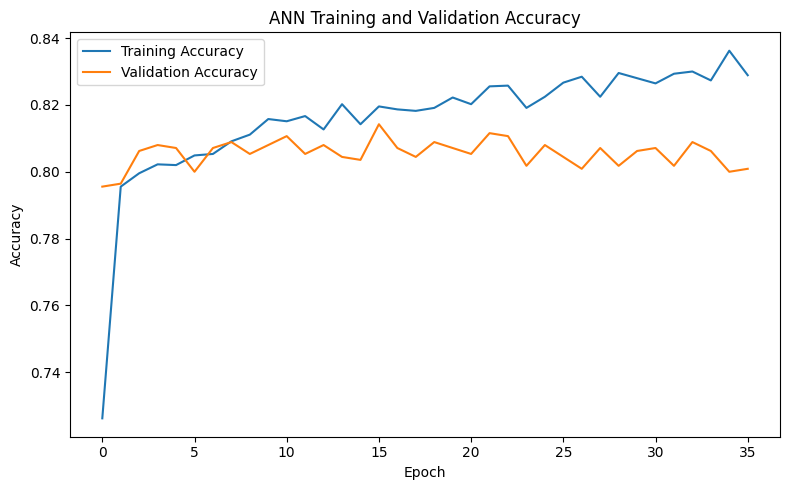

In [85]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history['accuracy'],
    label='Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Validation Accuracy'
)

plt.title('ANN Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

In [86]:
ann_prob = ann_model.predict(
    X_test_processed,
    verbose=0
).ravel()

ann_pred = (
    ann_prob >= 0.5
).astype(int)

print("ANN predictions generated successfully.")

ANN predictions generated successfully.


In [87]:
ann_result = evaluate_model(
    'ANN',
    y_test,
    ann_pred,
    ann_prob
)

ann_result_df = pd.DataFrame([ann_result])

display(
    ann_result_df.style.format({
        'Accuracy': '{:.4f}',
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'F1-Score': '{:.4f}',
        'ROC-AUC': '{:.4f}',
        'PR-AUC': '{:.4f}'
    })
)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,ANN,0.7974,0.6519,0.5107,0.5727,0.8390,0.6324


In [88]:
all_model_results = pd.concat(
    [
        baseline_df,
        xgb_result_df,
        ann_result_df
    ],
    ignore_index=True
)

display(
    all_model_results.style.format({
        'Accuracy': '{:.4f}',
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'F1-Score': '{:.4f}',
        'ROC-AUC': '{:.4f}',
        'PR-AUC': '{:.4f}'
    })
)

,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC
0,Decision Tree,0.7193,0.4733,0.4973,0.4850,0.6482,0.3690
1,Random Forest,0.7903,0.6304,0.5107,0.5643,0.8278,0.6083
2,SVM,0.7960,0.6426,0.5241,0.5773,0.8011,0.6220
3,XGBoost,0.7989,0.6383,0.5615,0.5974,0.8455,0.6560
4,ANN,0.7974,0.6519,0.5107,0.5727,0.8390,0.6324


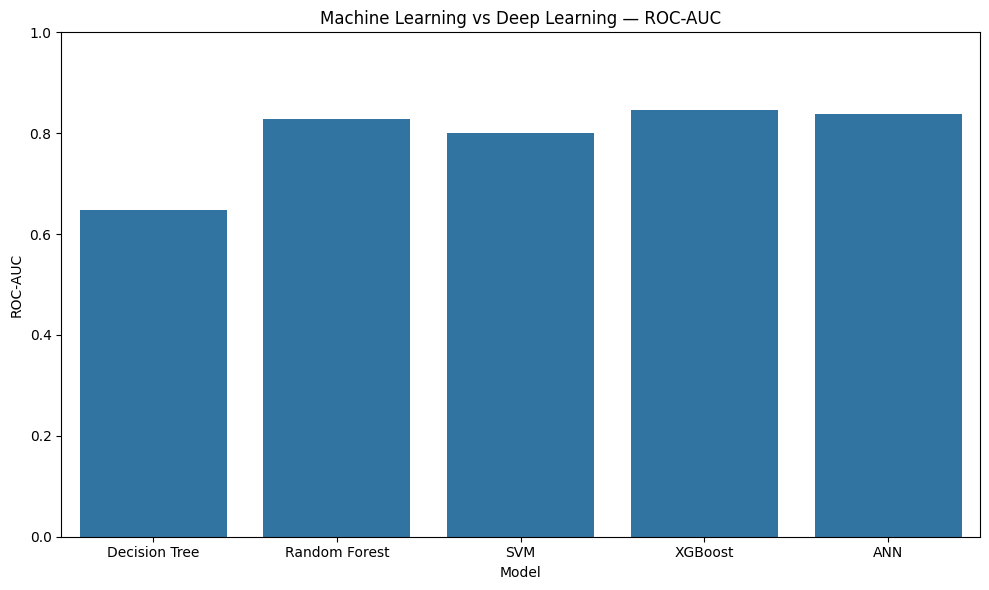

In [89]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=all_model_results,
    x='Model',
    y='ROC-AUC'
)

plt.title('Machine Learning vs Deep Learning — ROC-AUC')
plt.xlabel('Model')
plt.ylabel('ROC-AUC')
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

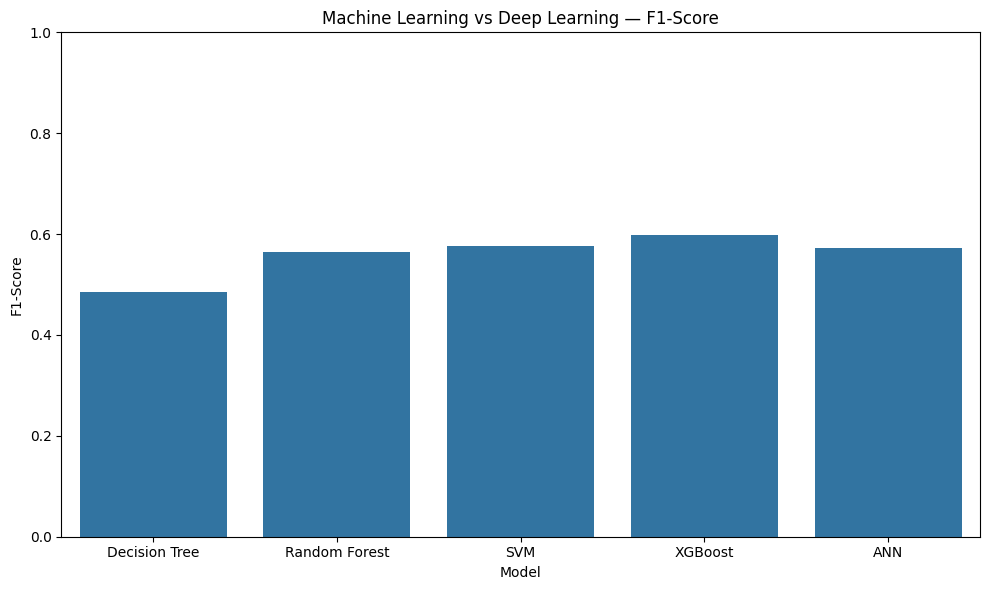

In [90]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=all_model_results,
    x='Model',
    y='F1-Score'
)

plt.title('Machine Learning vs Deep Learning — F1-Score')
plt.xlabel('Model')
plt.ylabel('F1-Score')
plt.ylim(0, 1)

plt.tight_layout()
plt.show()

## XGBoost Hyperparameter Tuning

XGBoost achieved the strongest baseline performance among the evaluated models.
To improve its generalization performance, hyperparameter tuning is performed
using GridSearchCV with stratified 5-fold cross-validation.

ROC-AUC is used as the optimization metric because the dataset is imbalanced
and the objective is to distinguish churners from non-churners effectively.

In [91]:
# ============================================================
# FINAL MODEL — NO CLTV, LEAKAGE-SAFE CROSS-VALIDATION
# ============================================================

from pathlib import Path
import joblib
import pandas as pd
import numpy as np

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

from xgboost import XGBClassifier

# ------------------------------------------------------------
# 1. Verify model inputs
# ------------------------------------------------------------

assert "CLTV" not in X_train.columns, (
    "CLTV must be excluded from model training."
)

assert "CLTV" not in X_test.columns, (
    "CLTV must be excluded from model testing."
)

assert X_train.shape[1] == 19, (
    f"Expected 19 raw predictors, found {X_train.shape[1]}."
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Raw predictors:", X_train.shape[1])
print("CLTV included:", "CLTV" in X_train.columns)

# ------------------------------------------------------------
# 2. Build preprocessing and model pipeline
#    Preprocessing is fitted separately within each CV fold.
# ------------------------------------------------------------

numeric_features = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = [
    col for col in X_train.columns
    if col not in numeric_features
]

preprocessor_template = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first",
                sparse_output=False
            ),
            categorical_features
        )
    ],
    remainder="drop"
)

xgb_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor_template),
        (
            "classifier",
            XGBClassifier(
                objective="binary:logistic",
                eval_metric="logloss",
                random_state=42,
                n_jobs=1
            )
        )
    ]
)

# ------------------------------------------------------------
# 3. Hyperparameter tuning
# ------------------------------------------------------------

xgb_param_grid = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [3, 4, 5],
    "classifier__learning_rate": [0.03, 0.05, 0.1],
    "classifier__subsample": [0.8, 1.0],
    "classifier__colsample_bytree": [0.8, 1.0]
}

cv_strategy = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

xgb_grid = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid=xgb_param_grid,
    scoring="roc_auc",
    cv=cv_strategy,
    n_jobs=-1,
    refit=True,
    verbose=1
)

xgb_grid.fit(X_train, y_train)

best_pipeline = xgb_grid.best_estimator_

# Keep these variable names for subsequent notebook cells.
preprocessor = best_pipeline.named_steps["preprocessor"]
best_xgb = best_pipeline.named_steps["classifier"]

best_params = {
    key.replace("classifier__", ""): value
    for key, value in xgb_grid.best_params_.items()
}

print("\nBest Parameters:")
print(best_params)

print("\nBest 5-Fold CV ROC-AUC:")
print(f"{xgb_grid.best_score_:.4f}")

# ------------------------------------------------------------
# 4. Transform using the selected pipeline's fitted preprocessor
# ------------------------------------------------------------

X_train_processed = preprocessor.transform(X_train)
X_test_processed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()

print("\nProcessed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)
print("Processed feature count:", len(feature_names))

assert X_train_processed.shape[1] == best_xgb.n_features_in_
assert X_test_processed.shape[1] == best_xgb.n_features_in_

# ------------------------------------------------------------
# 5. Evaluate on the held-out test set
# ------------------------------------------------------------

xgb_test_pred = best_xgb.predict(X_test_processed)

xgb_test_prob = best_xgb.predict_proba(
    X_test_processed
)[:, 1]

xgb_accuracy = accuracy_score(y_test, xgb_test_pred)
xgb_precision = precision_score(
    y_test, xgb_test_pred, zero_division=0
)
xgb_recall = recall_score(
    y_test, xgb_test_pred, zero_division=0
)
xgb_f1 = f1_score(
    y_test, xgb_test_pred, zero_division=0
)
xgb_roc_auc = roc_auc_score(y_test, xgb_test_prob)
xgb_pr_auc = average_precision_score(y_test, xgb_test_prob)

print("\nFinal XGBoost — No CLTV")
print("=" * 45)
print(f"Accuracy : {xgb_accuracy:.4f}")
print(f"Precision: {xgb_precision:.4f}")
print(f"Recall   : {xgb_recall:.4f}")
print(f"F1 Score : {xgb_f1:.4f}")
print(f"ROC-AUC  : {xgb_roc_auc:.4f}")
print(f"PR-AUC   : {xgb_pr_auc:.4f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        xgb_test_pred,
        target_names=["No Churn", "Churn"],
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, xgb_test_pred))

# ------------------------------------------------------------
# 6. Save the exact model and matching preprocessor
# ------------------------------------------------------------

# Supports running the notebook from either the project root
# or the Notebook directory.
candidate_dirs = [
    Path("Streamlit App/models"),
    Path("../Streamlit App/models")
]

model_dir = next(
    (path for path in candidate_dirs if path.parent.exists()),
    candidate_dirs[0]
)

model_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(
    best_xgb,
    model_dir / "best_xgb_model.pkl"
)

joblib.dump(
    preprocessor,
    model_dir / "preprocessor.pkl"
)

print("\nModel artifacts saved:")
print(model_dir / "best_xgb_model.pkl")
print(model_dir / "preprocessor.pkl")

print("\nFinal model expects 19 raw predictors and excludes CLTV.")

Training rows: 5625
Testing rows: 1407
Raw predictors: 19
CLTV included: False
Fitting 5 folds for each of 108 candidates, totalling 540 fits

Best Parameters:
{'colsample_bytree': 1.0, 'learning_rate': 0.03, 'max_depth': 4, 'n_estimators': 200, 'subsample': 0.8}

Best 5-Fold CV ROC-AUC:
0.8658

Processed training shape: (5625, 30)
Processed testing shape: (1407, 30)
Processed feature count: 30

Final XGBoost — No CLTV
Accuracy : 0.8017
Precision: 0.6453
Recall   : 0.5642
F1 Score : 0.6020
ROC-AUC  : 0.8496
PR-AUC   : 0.6670

Classification Report:
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1033
       Churn       0.65      0.56      0.60       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.73      1407
weighted avg       0.79      0.80      0.80      1407


Confusion Matrix:
[[917 116]
 [163 211]]

Model artifacts saved:
Streamlit App/models/best_xgb_model.pkl
Streamlit Ap

## XGBoost Evaluation Visualizations

<Figure size 600x500 with 0 Axes>

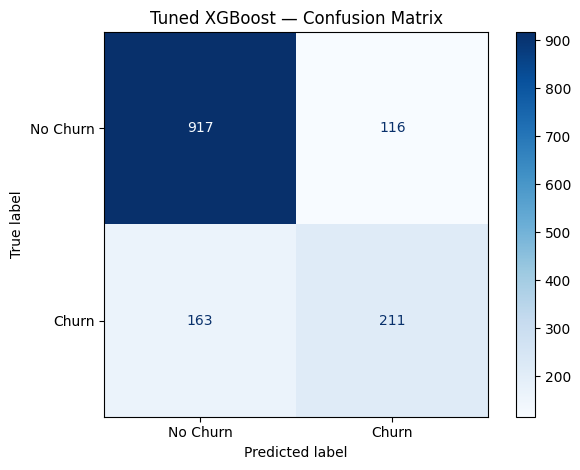

In [92]:
from sklearn.metrics import ConfusionMatrixDisplay

plt.figure(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    xgb_test_pred,
    display_labels=["No Churn", "Churn"],
    cmap="Blues"
)

plt.title("Tuned XGBoost — Confusion Matrix")
plt.tight_layout()
plt.show()

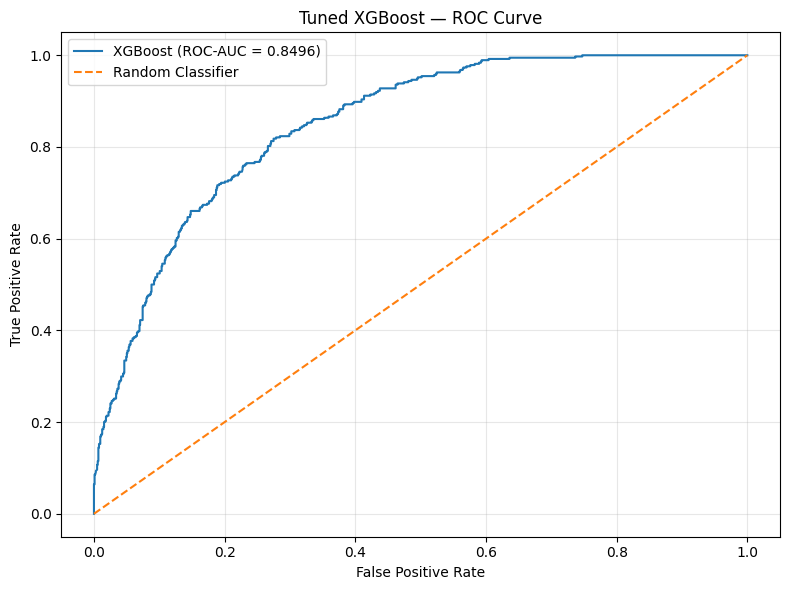

In [93]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, thresholds = roc_curve(y_test, xgb_test_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"XGBoost (ROC-AUC = {roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Tuned XGBoost — ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

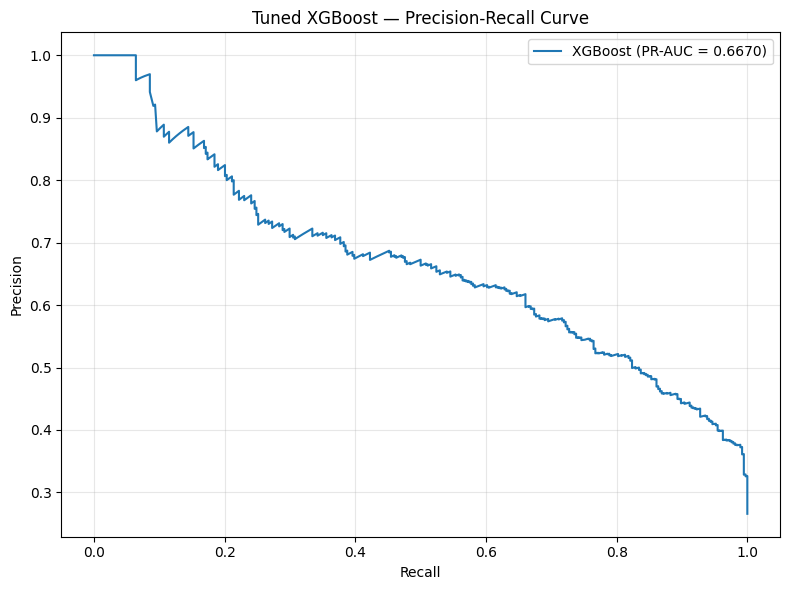

In [94]:
from sklearn.metrics import precision_recall_curve

precision, recall, _ = precision_recall_curve(
    y_test,
    xgb_test_prob
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall,
    precision,
    label=f"XGBoost (PR-AUC = {xgb_pr_auc:.4f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Tuned XGBoost — Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [95]:
# Get the feature names generated by the preprocessing pipeline
feature_names = preprocessor.get_feature_names_out()

print("Number of feature names:", len(feature_names))
print("Number of importances:", len(best_xgb.feature_importances_))

Number of feature names: 30
Number of importances: 30


In [96]:
# XGBoost feature importance
xgb_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': best_xgb.feature_importances_
}).sort_values(
    by='Importance',
    ascending=False
)

print("Top 15 XGBoost Features:")
display(xgb_importance.head(15))

Top 15 XGBoost Features:


,Feature,Importance
10,cat__Internet Service_Fiber optic,0.257499
25,cat__Contract_Two year,0.148601
24,cat__Contract_One year,0.126662
11,cat__Internet Service_No,0.063590
0,num__Tenure Months,0.056751
6,cat__Dependents_Yes,0.053948
28,cat__Payment Method_Electronic check,0.047150
23,cat__Streaming Movies_Yes,0.027944
13,cat__Online Security_Yes,0.025744
21,cat__Streaming TV_Yes,0.024138


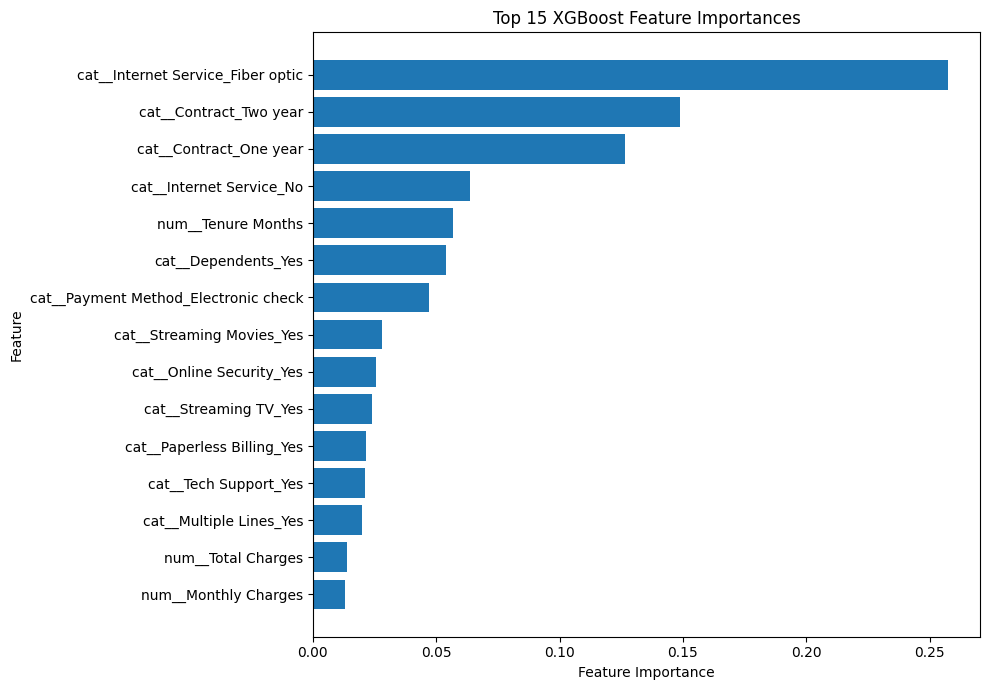

In [97]:
plt.figure(figsize=(10, 7))

top_features = xgb_importance.head(15).sort_values(
    by='Importance'
)

plt.barh(
    top_features['Feature'],
    top_features['Importance']
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 15 XGBoost Feature Importances")

plt.tight_layout()
plt.show()

## **Phase 2 — Explainable AI (SHAP)**

In [98]:
import shap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("SHAP version:", shap.__version__)

SHAP version: 0.51.0


In [99]:
# Create SHAP Tree Explainer for the tuned XGBoost model
explainer = shap.TreeExplainer(best_xgb)

# Calculate SHAP values for the test set
shap_values = explainer.shap_values(X_test_processed)

print("SHAP values shape:", shap_values.shape)
print("Test data shape:", X_test_processed.shape)

SHAP values shape: (1407, 30)
Test data shape: (1407, 30)


In [100]:
# Get feature names from the fitted preprocessing pipeline
feature_names = preprocessor.get_feature_names_out()

print("Number of feature names:", len(feature_names))
print("\nFeature names:")
print(feature_names)

Number of feature names: 30

Feature names:
['num__Tenure Months' 'num__Monthly Charges' 'num__Total Charges'
 'cat__Gender_Male' 'cat__Senior Citizen_Yes' 'cat__Partner_Yes'
 'cat__Dependents_Yes' 'cat__Phone Service_Yes'
 'cat__Multiple Lines_No phone service' 'cat__Multiple Lines_Yes'
 'cat__Internet Service_Fiber optic' 'cat__Internet Service_No'
 'cat__Online Security_No internet service' 'cat__Online Security_Yes'
 'cat__Online Backup_No internet service' 'cat__Online Backup_Yes'
 'cat__Device Protection_No internet service' 'cat__Device Protection_Yes'
 'cat__Tech Support_No internet service' 'cat__Tech Support_Yes'
 'cat__Streaming TV_No internet service' 'cat__Streaming TV_Yes'
 'cat__Streaming Movies_No internet service' 'cat__Streaming Movies_Yes'
 'cat__Contract_One year' 'cat__Contract_Two year'
 'cat__Paperless Billing_Yes'
 'cat__Payment Method_Credit card (automatic)'
 'cat__Payment Method_Electronic check' 'cat__Payment Method_Mailed check']


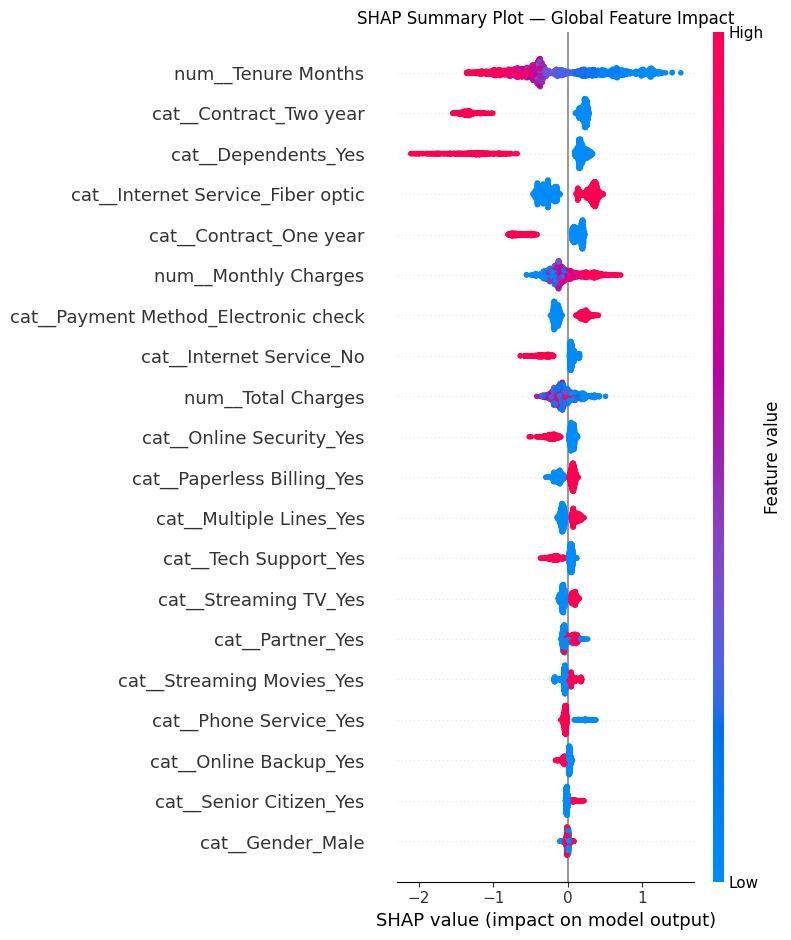

In [101]:
# SHAP Summary Plot — Global Feature Impact

plt.figure(figsize=(10, 7))

shap.summary_plot(
    shap_values,
    X_test_processed,
    feature_names=feature_names,
    show=False
)

plt.title("SHAP Summary Plot — Global Feature Impact")
plt.tight_layout()
plt.show()

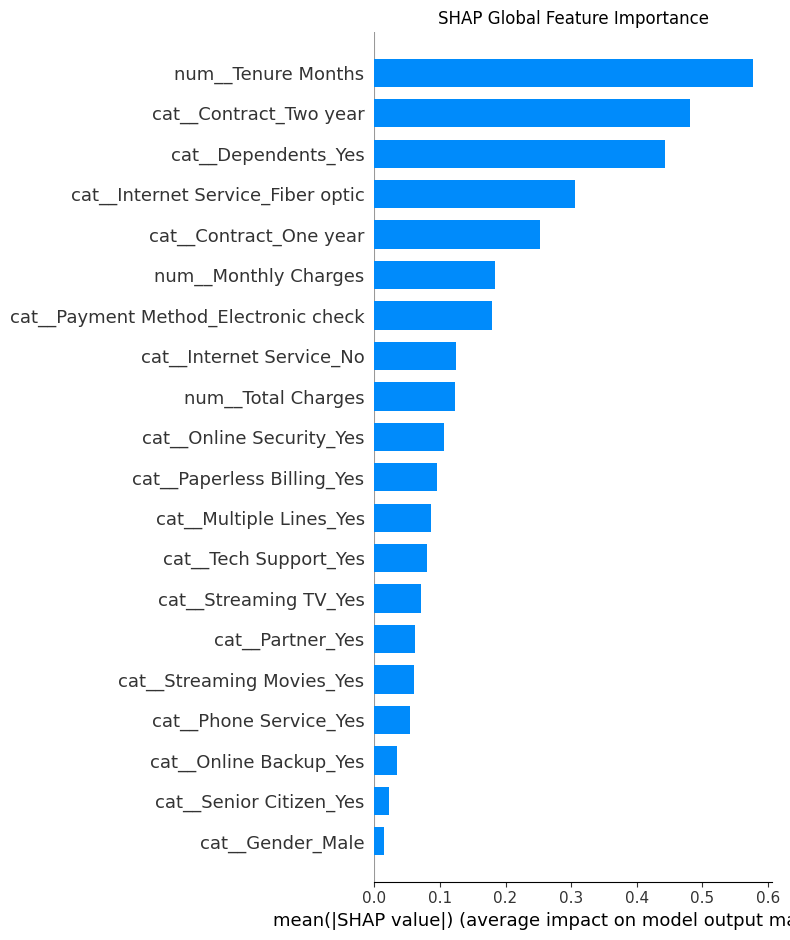

In [102]:
# SHAP Global Feature Importance

plt.figure(figsize=(10, 7))

shap.summary_plot(
    shap_values,
    X_test_processed,
    feature_names=feature_names,
    plot_type="bar",
    show=False
)

plt.title("SHAP Global Feature Importance")
plt.tight_layout()
plt.show()

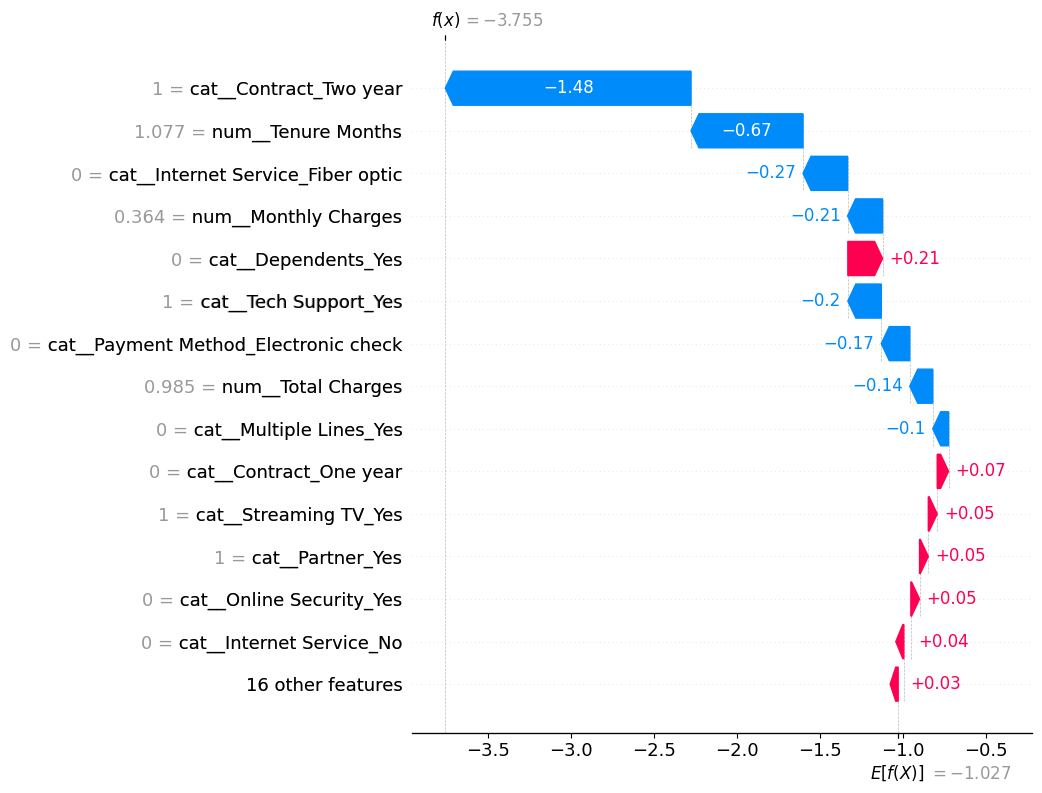

In [103]:
# Select one customer from the test set
customer_index = 0

# Create SHAP explanation object
customer_explanation = shap.Explanation(
    values=shap_values[customer_index],
    base_values=explainer.expected_value,
    data=X_test_processed[customer_index],
    feature_names=feature_names
)

# Waterfall plot for the selected customer
shap.plots.waterfall(customer_explanation, max_display=15)

In [104]:
# Select the same customer
customer_index = 0

# Get churn probability
customer_probability = best_xgb.predict_proba(
    X_test_processed[customer_index].reshape(1, -1)
)[0, 1]

# Get predicted class
customer_prediction = best_xgb.predict(
    X_test_processed[customer_index].reshape(1, -1)
)[0]

# Get actual class
customer_actual = y_test.iloc[customer_index]

print("Customer Risk Explanation")
print("=" * 40)

print(f"Actual Churn: {'Yes' if customer_actual == 1 else 'No'}")
print(f"Predicted Churn: {'Yes' if customer_prediction == 1 else 'No'}")
print(f"Predicted Churn Probability: {customer_probability:.2%}")

Customer Risk Explanation
Actual Churn: No
Predicted Churn: No
Predicted Churn Probability: 2.29%


In [105]:
# Create a dataframe containing SHAP contributions
customer_shap = pd.DataFrame({
    'Feature': feature_names,
    'SHAP Value': shap_values[customer_index]
})

# Features increasing churn risk
increasing_risk = (
    customer_shap[customer_shap['SHAP Value'] > 0]
    .sort_values('SHAP Value', ascending=False)
)

# Features decreasing churn risk
decreasing_risk = (
    customer_shap[customer_shap['SHAP Value'] < 0]
    .sort_values('SHAP Value')
)

print("\nTop Factors Increasing Churn Risk:")
print(increasing_risk.head(5).to_string(index=False))

print("\nTop Factors Decreasing Churn Risk:")
print(decreasing_risk.head(5).to_string(index=False))


Top Factors Increasing Churn Risk:
                 Feature  SHAP Value
     cat__Dependents_Yes    0.209146
  cat__Contract_One year    0.068206
   cat__Streaming TV_Yes    0.053726
        cat__Partner_Yes    0.052792
cat__Online Security_Yes    0.052440

Top Factors Decreasing Churn Risk:
                          Feature  SHAP Value
           cat__Contract_Two year   -1.479910
               num__Tenure Months   -0.674759
cat__Internet Service_Fiber optic   -0.268352
             num__Monthly Charges   -0.210753
            cat__Tech Support_Yes   -0.201409


<Figure size 900x600 with 0 Axes>

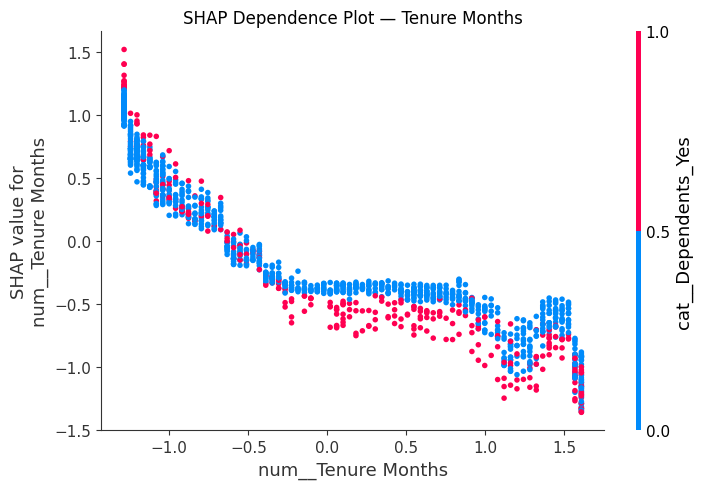

In [106]:
# SHAP Dependence Plot for Tenure Months

tenure_index = list(feature_names).index('num__Tenure Months')

plt.figure(figsize=(9, 6))

shap.dependence_plot(
    tenure_index,
    shap_values,
    X_test_processed,
    feature_names=feature_names,
    show=False
)

plt.title("SHAP Dependence Plot — Tenure Months")
plt.tight_layout()
plt.show()

In [107]:
# Create SHAP global importance table

shap_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Mean Absolute SHAP': np.abs(shap_values).mean(axis=0)
}).sort_values(
    'Mean Absolute SHAP',
    ascending=False
).reset_index(drop=True)

# Add rank
shap_importance_df.insert(
    0,
    'Rank',
    range(1, len(shap_importance_df) + 1)
)

print("Top 15 SHAP Features:")
display(shap_importance_df.head(15))

Top 15 SHAP Features:


,Rank,Feature,Mean Absolute SHAP
0,1,num__Tenure Months,0.577643
1,2,cat__Contract_Two year,0.481501
2,3,cat__Dependents_Yes,0.443574
3,4,cat__Internet Service_Fiber optic,0.305341
4,5,cat__Contract_One year,0.252075
5,6,num__Monthly Charges,0.184620
6,7,cat__Payment Method_Electronic check,0.179517
7,8,cat__Internet Service_No,0.124156
8,9,num__Total Charges,0.123267
9,10,cat__Online Security_Yes,0.105922


In [108]:
# Save SHAP importance results
shap_importance_df.to_csv(
    "shap_global_feature_importance.csv",
    index=False
)

print("SHAP importance table saved successfully.")

SHAP importance table saved successfully.


## Tableau Business Intelligence Dashboard

In [109]:
# ============================================
# PHASE 3 — STEP 1
# Prepare Tableau Dataset
# ============================================

# Copy the original feature data
tableau_df = X_test.copy()

# Add actual churn
tableau_df['Actual Churn'] = y_test.values

# Add XGBoost predicted probability
tableau_df['Churn Probability'] = best_xgb.predict_proba(
    X_test_processed
)[:, 1]

# Add predicted churn class
tableau_df['Predicted Churn'] = best_xgb.predict(
    X_test_processed
)

# Convert labels to readable values
tableau_df['Actual Churn'] = tableau_df['Actual Churn'].map({
    0: 'No',
    1: 'Yes'
})

tableau_df['Predicted Churn'] = tableau_df['Predicted Churn'].map({
    0: 'No',
    1: 'Yes'
})

# Convert probability to percentage
tableau_df['Churn Probability (%)'] = (
    tableau_df['Churn Probability'] * 100
).round(2)

print("Tableau dataset shape:", tableau_df.shape)

display(tableau_df.head())

Tableau dataset shape: (1407, 23)


,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Actual Churn,Churn Probability,Predicted Churn,Churn Probability (%)
2595,Female,No,Yes,No,59,Yes,No,DSL,No,Yes,No,Yes,Yes,Yes,Two year,Yes,Credit card (automatic),75.95,4542.35,No,0.022871,No,2.290000
2337,Female,No,No,No,7,Yes,Yes,Fiber optic,No,Yes,No,No,No,No,Month-to-month,Yes,Bank transfer (automatic),78.55,522.95,No,0.660213,Yes,66.019997
5032,Female,No,No,No,54,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.10,1079.45,No,0.022054,No,2.210000
975,Female,No,No,No,2,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Month-to-month,No,Mailed check,20.65,38.70,Yes,0.158453,No,15.850000
5212,Female,No,Yes,No,71,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Two year,Yes,Bank transfer (automatic),105.15,7555.00,No,0.162429,No,16.240000


In [110]:
# Create business-friendly churn risk categories

tableau_df['Risk Category'] = pd.cut(
    tableau_df['Churn Probability'],
    bins=[-np.inf, 0.30, 0.60, np.inf],
    labels=['Low Risk', 'Medium Risk', 'High Risk']
)

print(tableau_df['Risk Category'].value_counts())

Risk Category
Low Risk       830
Medium Risk    363
High Risk      214
Name: count, dtype: int64


In [111]:
from pathlib import Path

candidate_dirs = [
    Path("Data"),
    Path("../Data")
]

data_dir = next(
    (path for path in candidate_dirs if path.exists()),
    candidate_dirs[0]
)

data_dir.mkdir(parents=True, exist_ok=True)

tableau_path = data_dir / "customer_churn_tableau.csv"

tableau_df.to_csv(tableau_path, index=False)

print("Tableau dataset saved to:", tableau_path)
print("Rows:", len(tableau_df))
print("CLTV included:", "CLTV" in tableau_df.columns)

Tableau dataset saved to: Data/customer_churn_tableau.csv
Rows: 1407
CLTV included: False


In [112]:
import shutil
from google.colab import files

archive_path = shutil.make_archive(
    "churn_model_artifacts",
    "zip",
    root_dir=str(model_dir)
)

files.download(archive_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>